# H15 Part A · step 5 · 06 · What the side-car predicts, at three sizes, on the select logs

**What this notebook is.** The review of step 5 (plan §6.6): the side-car trained at three sizes, and a close
look at what each one predicts. It reads the runs' own files and their saved weights; nothing here trains.
- **5a:** v1 (4.39 M parameters), v2 (8.37 M) and v3 (18.44 M) at seed 0 for 12 epochs, and v1 for 24. They
  choose the variant and the schedule, by the rules committed in PREDICTIONS.md before any of them ran.
- **5b:** the chosen variant on the chosen schedule (v3 for 24 epochs) at seeds 0, 1 and 2, and the same
  side-car trained without the camera (its tokens zeroed), which shows what can be learnt from the labels
  alone.

**Every number is on the select logs** (51 held-out navtrain logs, 4,457 samples), the split the choices are
made on. The report logs are read once, at step 6, after this review (plan §8.1). A number here is a reading
of the split that chose the epoch and the variant, so it flatters the chosen ones a little; step 6's report
numbers are the results.

**Kernel:** `drive-jepa-v2` ("Drive-JEPA v2"), which starts `[python] drivejepa` and shows only GPU 1.
Headless: `scripts/run_notebooks.py`, run with that interpreter.

**Contents**
1. The runs, the gates, and the choices
2. How each run trained
3. The sizes side by side
4. The predictions, drawn
5. What it misses
6. What it gets wrong: the false alarms
7. Where its boxes go wrong: depth, not direction
8. Motion: velocity and the 1 s path
9. Confidence: ranking and calibration
10. The slots: duplicates, slot use, and what each decoder layer adds
11. What matters: causal, visible, nearest, pedestrian groups, traffic side
12. Does it use the camera geometry now?
13. Where it looked: cross-attention
14. Summary for the review

In [1]:
import json
import math
import os
import pickle
import re
import sys
import warnings
from pathlib import Path

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "gallops").is_dir())
sys.path.insert(0, str(REPO / "src"))
os.environ.setdefault("GALLOPS_CONFIG", str(REPO / "gallops.toml"))
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Polygon
from matplotlib.ticker import FuncFormatter

from gallops.config import SiteConfig
from gallops.drivejepa_perception import evaluate, navsim_data, views
from gallops.drivejepa_perception import importance as im
from gallops.drivejepa_perception import targets as tg
from gallops.drivejepa_perception import train_sidecar as ts

views.use_style()
pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 20)
cfg = SiteConfig.load()
RUNS = Path(cfg.resolve("{runs}")) / "drivejepa_perception"
PART_A = RUNS / "part-a"
NAVSIM = Path(cfg.resolve("{data.navsim}"))

labels = dict(np.load(RUNS / "labels-v1" / "labels.npz"))
logs = json.loads((RUNS / "labels-v1" / "manifest.json").read_text())["logs"]
token_logs = np.array([logs[i] for i in labels["log_id"]])
splits = json.loads((REPO / "recipes" / "drivejepa_perception" / "splits.json").read_text())
select = np.flatnonzero(np.isin(token_logs, splits["select"]))
# The trainer's own inputs: float32 projections, and targets built from them (train_sidecar.load).
proj = tg.front_projection(np.load(RUNS / "tokens-v1" / "lidar2img.npy")).astype(np.float32)
vit = np.load(RUNS / "tokens-vit-v1" / "vit_out.npy", mmap_mode="r")
gts = [tg.build(navsim_data.agents_of(labels, r), proj[r]) for r in select]
ego = np.asarray(np.load(RUNS / "tokens-v1" / "ego_status.npy", mmap_mode="r")[select, -1, 3:5])
ego_speed = np.hypot(ego[:, 0], ego[:, 1])
sample_log = token_logs[select]
print(f"select: {len(select):,} samples from {len(splits['select'])} logs, "
      f"{sum(int(g['mask'].sum()) for g in gts):,} targets")


def y_axis_left(ax):
    """Bird's-eye axes plot -y to the right, so left is left; the tick labels then show y itself."""
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{-v + 0.0:g}"))  # + 0.0: no "-0"
    ax.set_xlabel("y (m): + left, − right")
    ax.set_ylabel("x (m), forward")

select: 4,457 samples from 51 logs, 32,375 targets


## 1. The runs, the gates, and the choices

Every run of step 5 that has finished, read from its own files: `run.json` (arguments, preflight report),
`metrics.jsonl` (each epoch's select readout), `steps.jsonl` (every 50 steps) and `summary.json` (the kept
epoch). The kept epoch is the one with the best select F1 at 2 m within 30 m; the last epoch, which nothing
chose, is shown beside it.

In [2]:
RUN_GLOB = "5[ab]-*"
VARIANT_ORDER = ("v1", "v2", "v3")
#: One colour per variant: categorical slots 7, 5 and 4 of the reference palette, which pass its validator
#: all-pairs and stay apart from the class colours (blue, orange, aqua) and from hit and miss. A run on
#: another schedule keeps its variant's colour, dashed; another seed, dotted; no camera, grey.
VARIANT_COLOURS = {"v1": "#6250d6", "v2": "#e87ba4", "v3": "#eda100"}


def run_label(args):
    """A run's name here: its variant, then what differs from 5a's 12 epochs at seed 0."""
    name = args["variant"]
    if args["epochs"] != 12:
        name += f", {args['epochs']} epochs"
    if args.get("blind"):
        name += ", no camera"
    if args["seed"]:
        name += f", seed {args['seed']}"
    return name


def read_jsonl(path):
    return [json.loads(line) for line in path.read_text().splitlines()]


found = []
for d in PART_A.glob(RUN_GLOB):
    if not d.is_dir():
        continue
    if not (d / "summary.json").exists():
        print(f"{d.name}: no summary yet (training, or stopped); left out")
        continue
    meta = json.loads((d / "run.json").read_text())
    a = meta["args"]
    found.append(((d.name[:2], VARIANT_ORDER.index(a["variant"]), a["epochs"], bool(a.get("blind")), a["seed"]), d, meta))
runs = {}
for _, d, meta in sorted(found, key=lambda t: t[0]):
    runs[run_label(meta["args"])] = {"dir": d, "meta": meta, "args": meta["args"],
                                     "summary": json.loads((d / "summary.json").read_text()),
                                     "metrics": read_jsonl(d / "metrics.jsonl"), "steps": read_jsonl(d / "steps.jsonl")}


def style(name):
    a = runs[name]["args"]
    if a.get("blind"):
        return {"color": views.GREY, "ls": "-."}
    return {"color": VARIANT_COLOURS[a["variant"]], "ls": ":" if a["seed"] else ("--" if a["epochs"] != 12 else "-")}


def legend_for(names):
    return [plt.Line2D([], [], lw=1.5, **style(n), label=n) for n in names]


def at(name, epoch):
    return runs[name]["metrics"][epoch - 1]


overview = {}
for name, r in runs.items():
    m, kept, last = r["metrics"], r["summary"]["kept_epoch"], r["summary"]["last_epoch"]
    steps = sum(e["steps"] for e in m)
    overview[name] = {
        "parameters (M)": r["meta"]["params"] / 1e6,
        "epochs": r["args"]["epochs"],
        "seed": r["args"]["seed"],
        "kept epoch": kept,
        "select F1, kept epoch": at(name, kept)["f1_30m"],
        "select F1, last epoch": at(name, last)["f1_30m"],
        "minutes": m[-1]["seconds"] / 60,
        "peak GPU memory (GB)": max(e["max_memory_gb"] for e in m),
        "skipped steps (%)": 100 * sum(e["skipped_steps"] for e in m) / steps,
        "clipped steps (%)": 100 * sum(e["clipped_steps"] for e in m) / steps,
        "trained at": r["meta"]["train_git_sha"],
    }
pd.DataFrame(overview)

,v1,"v1, 24 epochs",v2,v3,"v3, 24 epochs","v3, 24 epochs, seed 1","v3, 24 epochs, seed 2","v3, 24 epochs, no camera"
parameters (M),4.388,4.388,8.369,18.444,18.444,18.444,18.444,18.444
epochs,12,24,12,12,24,24,24,24
seed,0,0,0,0,0,1,2,0
kept epoch,11,23,12,12,24,21,24,23
"select F1, kept epoch",0.671,0.698,0.679,0.699,0.719,0.718,0.713,0.041
"select F1, last epoch",0.67,0.697,0.679,0.699,0.719,0.718,0.713,0.024
minutes,23.533,38.717,36.8,37.567,104.183,101.067,104.05,102.083
peak GPU memory (GB),3.735,3.735,3.735,3.735,3.735,3.735,3.735,3.735
skipped steps (%),0.045,0.045,0.057,0.068,0.054,0.051,0.051,0.122
clipped steps (%),0.091,0.059,1.099,0.969,0.731,1.725,1.028,94.68


**The gates** (PREDICTIONS.md, step 4), each read from the runs' files:

In [3]:
def overfit_step(path):
    found_ = re.findall(r"overfit check passed at step (\d+)", path.read_text()) if path.exists() else []
    return int(found_[-1]) if found_ else None


overfit = {"v1": overfit_step(PART_A / "r1-overfit.log"),  # step 3's check
           "v2": overfit_step(PART_A / "logs" / "overfit-v2.log"),
           "v3": overfit_step(PART_A / "logs" / "overfit-v3.log")}
def gate(holds, detail):
    return {"holds": "yes" if holds else "NO", "detail": detail}


gates = {
    "G1 · every preflight passed, its report in run.json": gate(
        all("preflight" in r["meta"] and not r["meta"]["preflight"]["problems"] for r in runs.values()),
        f"{len(runs)} runs, no problem listed"),
    "G2 · each variant passed the overfit check before its first run": gate(
        all(overfit[r["args"]["variant"]] is not None for r in runs.values()),
        ", ".join(f"{v} at step {s} of 4,000" for v, s in overfit.items() if s)),
    "G3 · no non-finite loss (it would stop the run); skipped steps under 1%": gate(
        all(r["summary"]["last_epoch"] == r["args"]["epochs"] and overview[n]["skipped steps (%)"] < 1
            for n, r in runs.items()),
        f"every run finished its schedule; skipped at most {max(o['skipped steps (%)'] for o in overview.values()):.2f}%, "
        f"clipped {min(o['clipped steps (%)'] for o in overview.values()):.1f}–{max(o['clipped steps (%)'] for o in overview.values()):.1f}%"),
}
if "v1" in runs and len(runs["v1"]["metrics"]) >= 11:
    f1_11 = at("v1", 11)["f1_30m"]
    gates["G5 · v1 seed 0 reproduces the first pass's A1 seed 0"] = gate(
        abs(f1_11 - 0.669) <= 0.01, f"select F1 at epoch 11: {f1_11:.3f}, against 0.669 ± 0.01")
pd.DataFrame(gates).T

,holds,detail
"G1 · every preflight passed, its report in run.json",yes,"8 runs, no problem listed"
G2 · each variant passed the overfit check before its first run,yes,"v1 at step 1300 of 4,000, v2 at step 1000 of 4..."
G3 · no non-finite loss (it would stop the run); skipped steps under 1%,yes,every run finished its schedule; skipped at mo...
G5 · v1 seed 0 reproduces the first pass's A1 seed 0,yes,"select F1 at epoch 11: 0.671, against 0.669 ± ..."


**The choices** (plan §6.5, committed in PREDICTIONS.md): the variant is the smallest within 0.01 F1 of the
best at its kept epoch, seed 0; the schedule is 24 epochs if v1 at 24 beats v1 at 12 by at least 0.01 F1.

In [4]:
size_runs = [v for v in VARIANT_ORDER if v in runs]
f1_kept = {v: overview[v]["select F1, kept epoch"] for v in size_runs}
best = max(f1_kept.values())
chosen = next(v for v in size_runs if f1_kept[v] >= best - 0.01)
choices = {"variant": {"rule": "smallest within 0.01 F1 of the best (seed 0, kept epochs)",
                       "read": ", ".join(f"{v} {f:.3f}" for v, f in f1_kept.items()), "chosen": chosen}}
schedule = 12
if "v1, 24 epochs" in runs and "v1" in runs:
    f24 = overview["v1, 24 epochs"]["select F1, kept epoch"]
    schedule = 24 if f24 >= f1_kept["v1"] + 0.01 else 12
    choices["schedule"] = {"rule": "24 epochs if v1-24 beats v1-12 by ≥ 0.01 F1",
                           "read": f"v1-24 {f24:.3f} against v1-12 {f1_kept['v1']:.3f} ({f24 - f1_kept['v1']:+.3f})",
                           "chosen": f"{schedule} epochs"}
# The run looked at closely from section 4 on: the chosen variant on the chosen schedule, seed 0 (5b), or
# the chosen variant's 5a run until 5b exists. `compare` is what the "every run" charts overlay.
focus = next((n for n, r in runs.items() if r["dir"].name.startswith("5b-") and r["args"]["variant"] == chosen
              and r["args"]["epochs"] == schedule and r["args"]["seed"] == 0 and not r["args"].get("blind")), chosen)
compare = [n for n in ("v1", "v2", "v3", "v1, 24 epochs") if n in runs]
compare += [focus] if focus not in compare else []
seed_runs = [n for n, r in runs.items() if r["args"]["variant"] == chosen and r["args"]["epochs"] == schedule
             and not r["args"].get("blind") and r["dir"].name.startswith("5b-")]
blind_runs = [n for n, r in runs.items() if r["args"].get("blind")]
print(f"looked at closely from section 4: {focus}; overlaid: {', '.join(compare)}")
pd.DataFrame(choices).T

looked at closely from section 4: v3, 24 epochs; overlaid: v1, v2, v3, v1, 24 epochs, v3, 24 epochs


,rule,read,chosen
variant,"smallest within 0.01 F1 of the best (seed 0, k...","v1 0.671, v2 0.679, v3 0.699",v3
schedule,24 epochs if v1-24 beats v1-12 by ≥ 0.01 F1,v1-24 0.698 against v1-12 0.671 (+0.027),24 epochs


Q7 and Q8 predicted these choices (they record a choice; they cannot be supported or refuted):

In [5]:
q = {}
if {"v1", "v2", "v3"} <= set(runs):
    q["Q7 · variant"] = {"predicted": "v2 beats v1 by 0.01–0.04 F1; v3 within 0.01 of v2",
                         "measured": f"v2 − v1 {f1_kept['v2'] - f1_kept['v1']:+.3f}; v3 − v2 {f1_kept['v3'] - f1_kept['v2']:+.3f}"}
if "schedule" in choices:
    q["Q8 · schedule"] = {"predicted": "24 beats 12 by 0.005–0.02 F1",
                          "measured": f"{overview['v1, 24 epochs']['select F1, kept epoch'] - f1_kept['v1']:+.3f}"}
pd.DataFrame(q).T

,predicted,measured
Q7 · variant,v2 beats v1 by 0.01–0.04 F1; v3 within 0.01 of v2,v2 − v1 +0.008; v3 − v2 +0.020
Q8 · schedule,24 beats 12 by 0.005–0.02 F1,+0.027


## 2. How each run trained

Plan §6.7's curves, every run on one set of axes. Training numbers are the means over each 50-step window
(`steps.jsonl`); the last decoder layer's terms are the ones the readout reads. The x axis is epochs, so a
24-epoch run is twice as long.

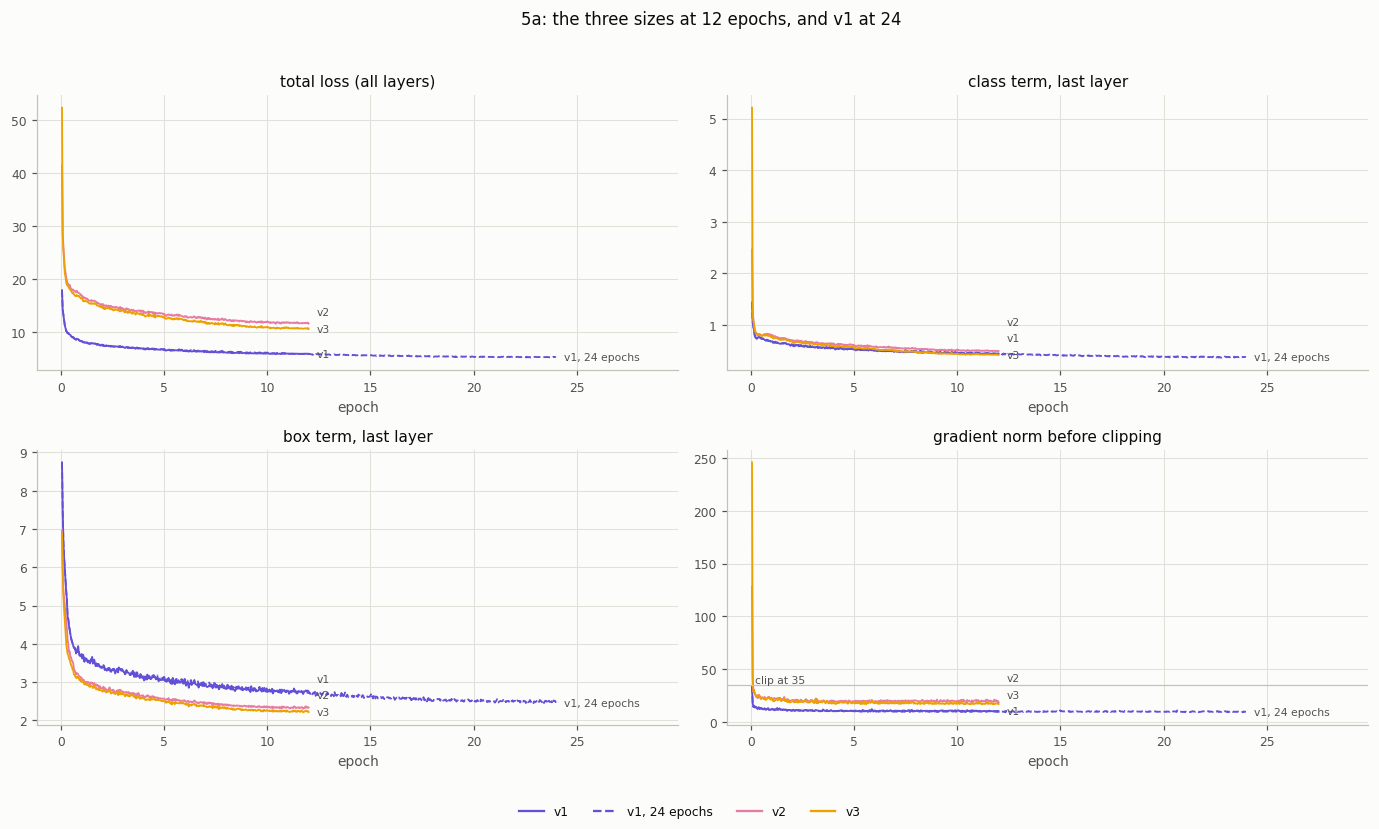

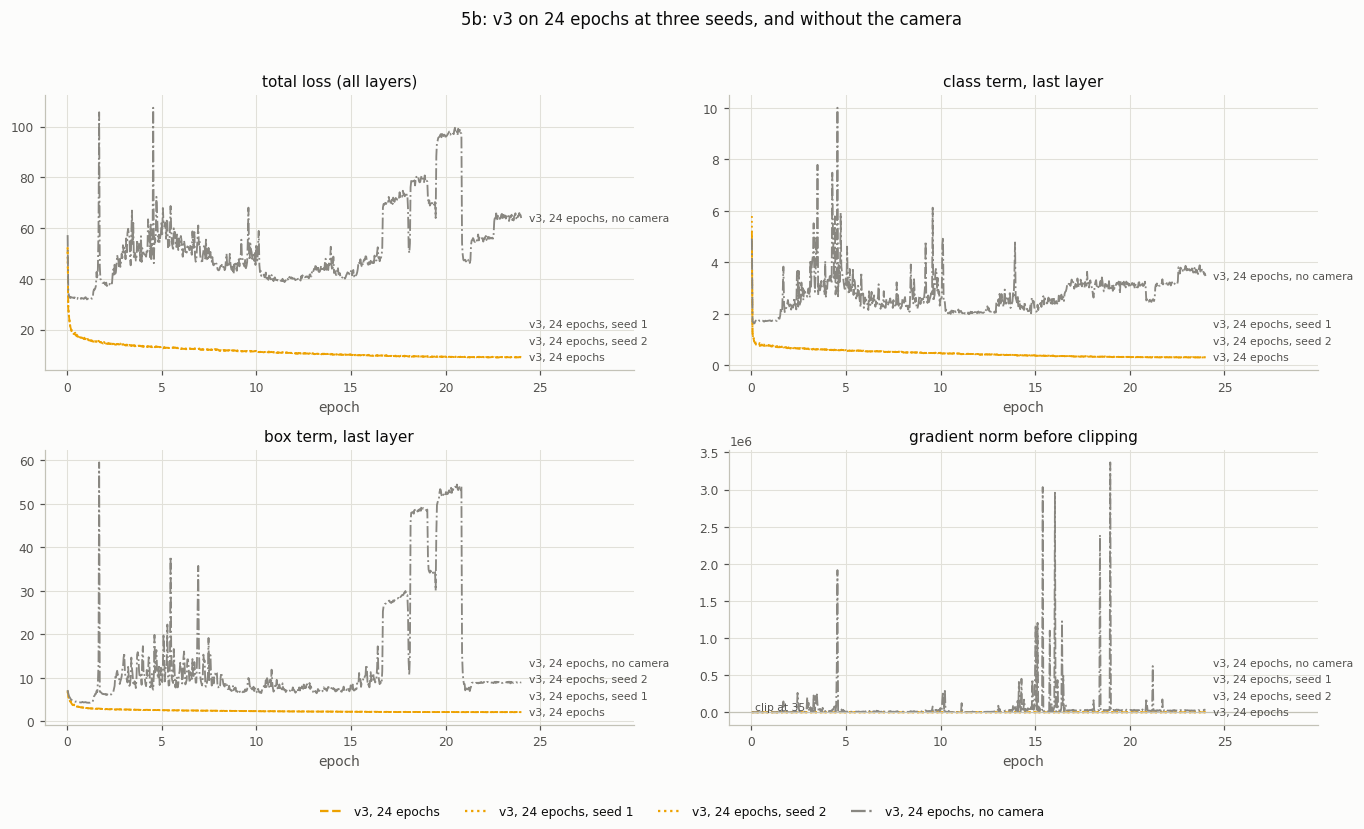

In [6]:
def label_ends(ax, ends):
    """Direct labels in ink at the right end of each line, nudged apart so they do not collide; the x axis
    is widened to make room for them."""
    ends = [e for e in ends if np.isfinite(e[2])]
    if not ends:
        return
    x0, x1 = ax.get_xlim()
    ax.set_xlim(x0, x1 + 0.18 * (x1 - x0))
    lo, hi = ax.get_ylim()
    gap = 0.06 * (hi - lo)
    # Lines that end at the same x share a column of labels; only those are nudged apart, and a column
    # that would leave the axes is shifted back inside.
    for x in sorted({e[1] for e in ends}):
        column = sorted([e for e in ends if e[1] == x], key=lambda e: e[2])
        placed = []
        for _, _, y in column:
            placed.append(max(y, placed[-1] + gap) if placed else y)
        shift = min(0.0, hi - gap / 2 - placed[-1])
        for (name, _, _), y_text in zip(column, placed):
            ax.text(x + 0.015 * (x1 - x0), y_text + shift, name, fontsize=7, color=views.INK_2, va="center", ha="left")


def train_curve(name, key):
    r = runs[name]
    per_epoch = r["meta"]["steps_per_epoch"]
    x = np.array([s["step"] for s in r["steps"]]) / per_epoch
    y = np.array([s.get(key, np.nan) for s in r["steps"]])
    return x, y


def training_curves(names, title):
    fig, axes = plt.subplots(2, 2, figsize=(13, 7.4))
    panels = [("loss", "total loss (all layers)"), ("cls", "class term, last layer"), ("box", "box term, last layer"),
              ("grad_norm", "gradient norm before clipping")]
    for ax, (key, sub_title) in zip(axes.ravel(), panels):
        ends = []
        for name in names:
            r = runs[name]
            k = f"{key}{r['args']['layers'] - 1}" if key in ("cls", "box") else key
            x, y = train_curve(name, k)
            ax.plot(x, y, lw=1.2, **style(name))
            ends.append((name, x[-1], y[-1]))
        if key == "grad_norm":
            ax.axhline(ts.CLIP, color=views.AXIS, lw=0.8)
            ax.text(0.2, ts.CLIP, "clip at 35", fontsize=7, color=views.INK_2, va="bottom")
        ax.set_title(sub_title)
        ax.set_xlabel("epoch")
        label_ends(ax, ends)
    fig.legend(handles=legend_for(names), loc="lower center", ncol=len(names))
    fig.suptitle(title, y=1.0)
    plt.tight_layout(rect=(0, 0.05, 0.97, 0.98))
    plt.show()


def select_curves(names, title):
    fig, axes = plt.subplots(2, 2, figsize=(13, 7.4))
    panels = [("f1_30m", "select F1 at 2 m within 30 m (● the kept epoch)"),
              ("recall_causal_chosen", "select recall of causal targets (chosen rule, all ranges)"),
              ("duplicate_pairs_per_sample", "pairs of same-class detections within 2 m, a sample"),
              ("detections_per_sample", "detections a sample")]
    for ax, (key, sub_title) in zip(axes.ravel(), panels):
        ends = []
        for name in names:
            r = runs[name]
            e = np.array([m["epoch"] for m in r["metrics"]])
            y = np.array([m["f1_30m"] if key == "f1_30m" else m["select"].get(key, np.nan) for m in r["metrics"]])
            ax.plot(e, y, marker="o", ms=3, lw=1.2, **style(name))
            if key == "f1_30m":
                k = r["summary"]["kept_epoch"]
                ax.plot(k, y[k - 1], "o", ms=8, color=style(name)["color"], mec=views.SURFACE, mew=1.5)
            ends.append((name, e[-1], y[-1]))
        if key == "detections_per_sample":
            ax.axhline(targets_per_sample, color=views.AXIS, lw=0.8)
            ax.text(1, targets_per_sample, f"targets a sample ({targets_per_sample:.1f})", fontsize=7,
                    color=views.INK_2, va="bottom")
        ax.set_title(sub_title)
        ax.set_xlabel("epoch")
        label_ends(ax, ends)
    fig.legend(handles=legend_for(names), loc="lower center", ncol=len(names))
    fig.suptitle(title, y=1.0)
    plt.tight_layout(rect=(0, 0.05, 0.97, 0.98))
    plt.show()


targets_per_sample = float(np.mean([g["mask"].sum() for g in gts]))
stage_5a = [n for n in runs if runs[n]["dir"].name.startswith("5a-")]
stage_5b = [n for n in runs if runs[n]["dir"].name.startswith("5b-")]
training_curves(stage_5a, "5a: the three sizes at 12 epochs, and v1 at 24")
if stage_5b:
    training_curves(stage_5b, f"5b: {chosen} on {schedule} epochs at three seeds, and without the camera")

**Reading it:**
- **Every run that sees the camera trains smoothly to the end of its schedule:** no loss stalls or rises,
  and none is non-finite. The total sums every layer's terms, so it is not comparable between 3 and 6
  layers; the last layer's terms are.
- **Training longer pays because the loss is still falling:** at epoch 12 of 24, v1's loss (5.94) is where
  v1 on 12 epochs ends (5.93), and it goes on to 5.32.
- **The gradient norm settles near 10, far under the clip of 35.** Each run clips 100–150 steps in its
  first epoch, then a few an epoch. In the 24-epoch runs clipping rises again over the second half, to
  14–49 steps an epoch (at most 3% of them).
- **The no-camera control is the exception** (5b's figure). Its loss rises and spikes (epoch means from
  33 to as much as 90), its gradient norm reaches 3 × 10⁶ before clipping, and 95% of its steps were
  clipped. Section 3 has what is known about why.

**Every epoch's select readout** (`metrics.jsonl`). The pairs panel counts two detections of one class
within 2 m of each other; section 10 splits them into real neighbours and true duplicates.

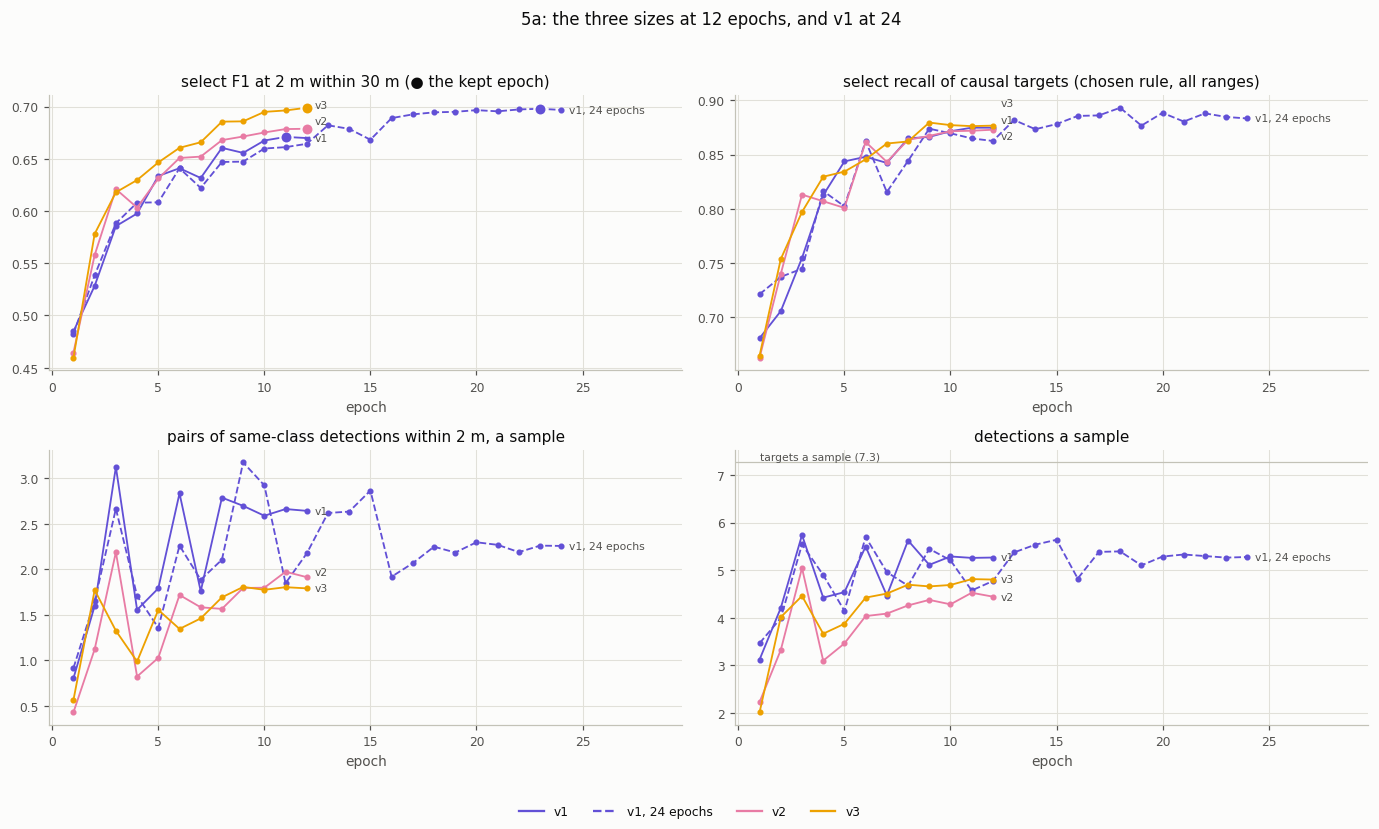

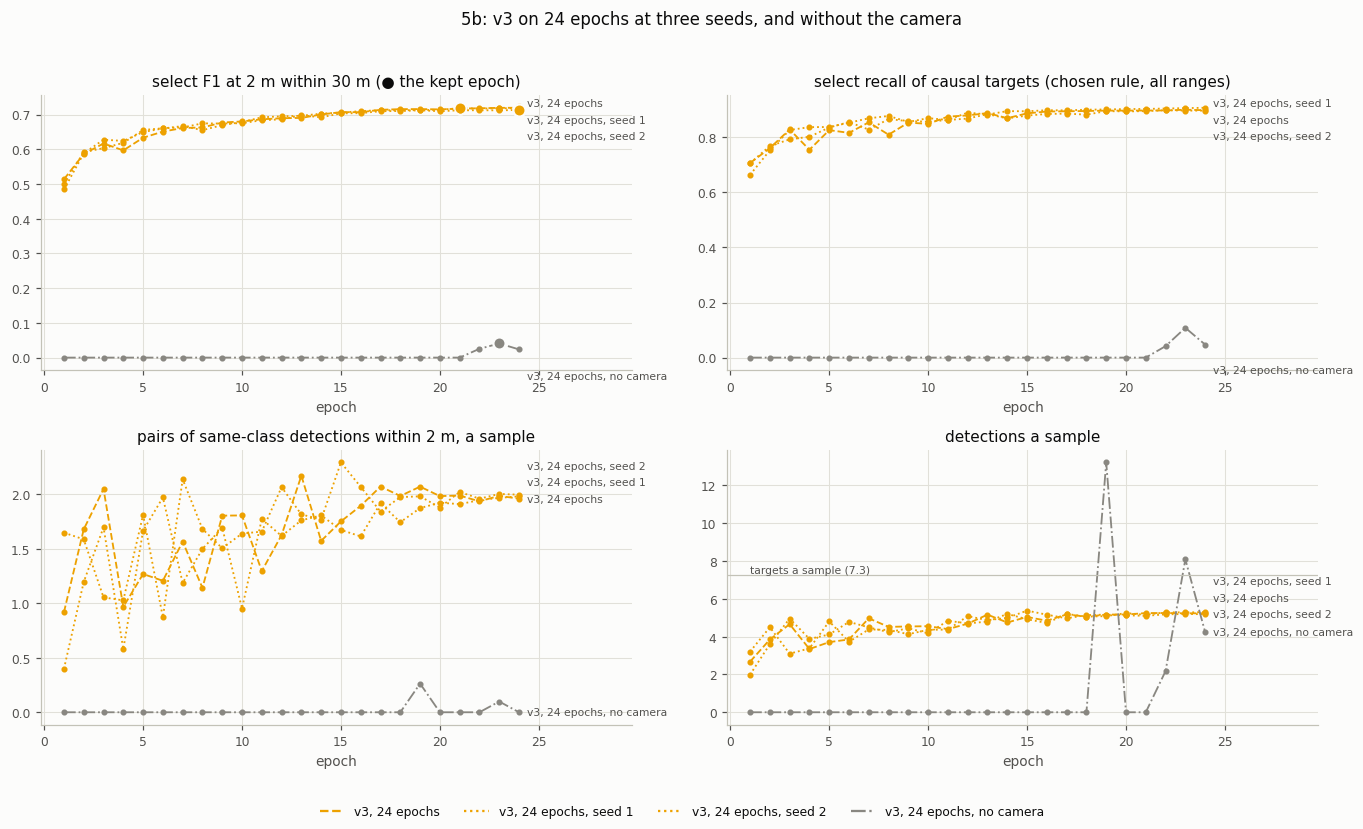

,epoch 1,epoch 2,epoch 3,epoch 4,epoch 5,epoch 6,epoch 7,epoch 8,epoch 9,epoch 10,...,epoch 15,epoch 16,epoch 17,epoch 18,epoch 19,epoch 20,epoch 21,epoch 22,epoch 23,epoch 24
v1,0.485,0.528,0.585,0.598,0.633,0.641,0.632,0.660,0.656,0.667,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
"v1, 24 epochs",0.483,0.538,0.588,0.608,0.608,0.641,0.622,0.647,0.647,0.660,...,0.668,0.689,0.692,0.694,0.695,0.697,0.695,0.697,0.698,0.697
v2,0.464,0.558,0.621,0.603,0.631,0.651,0.652,0.668,0.671,0.675,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
v3,0.460,0.578,0.618,0.630,0.646,0.660,0.666,0.686,0.686,0.695,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
"v3, 24 epochs",0.514,0.586,0.617,0.597,0.633,0.651,0.661,0.663,0.677,0.680,...,0.707,0.707,0.714,0.715,0.716,0.715,0.717,0.718,0.719,0.719
"v3, 24 epochs, seed 1",0.484,0.588,0.628,0.624,0.650,0.660,0.667,0.655,0.669,0.678,...,0.705,0.710,0.712,0.712,0.713,0.714,0.718,0.717,0.718,0.718
"v3, 24 epochs, seed 2",0.500,0.592,0.603,0.618,0.655,0.660,0.663,0.674,0.674,0.675,...,0.703,0.704,0.710,0.710,0.712,0.709,0.712,0.712,0.712,0.713
"v3, 24 epochs, no camera",0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.025,0.041,0.024


In [7]:
select_curves(stage_5a, "5a: the three sizes at 12 epochs, and v1 at 24")
if stage_5b:
    select_curves(stage_5b, f"5b: {chosen} on {schedule} epochs at three seeds, and without the camera")
pd.DataFrame({name: {f"epoch {m['epoch']}": m["f1_30m"] for m in r["metrics"]} for name, r in runs.items()}).T.round(3)

**Reading it:**
- **F1 rises fast for 3–5 epochs, then slowly, to the end.** Every kept epoch is the last or close to it
  (v1 11 of 12; v2 and v3 12; v1 on 24 epochs 23; v3 on 24 epochs 24, 21 and 24), and no curve turns down:
  no run has begun to overfit the select logs.
- **v3 leads the 12-epoch runs at every epoch but the third.** Its three 24-epoch seeds differ by up to
  0.03 in the first epochs and by under 0.01 from epoch 10 on.
- **Causal recall follows F1**, to about 0.875 after 12 epochs and 0.88–0.91 after 24.
- **Every run under-detects:** 4.4–5.3 detections a sample against 7.3 targets. Recall, not precision, is
  what limits F1.
- **Pairs of close same-class detections rise early** and end at 1.8–2.7 a sample. Section 10 shows that a
  third to two fifths of them are two real agents side by side, not duplicates.

## 3. The sizes side by side

Each run's kept epoch, run again here on the select logs (the same batches as the trainer's readout), so
every later section can look inside the predictions. First, that the numbers are the run's own:

In [8]:
def freest_device():
    if not torch.cuda.is_available():
        return torch.device("cpu")
    free = [torch.cuda.mem_get_info(i)[0] for i in range(torch.cuda.device_count())]
    return torch.device("cuda", int(np.argmax(free)))


device = freest_device()
TOK = np.stack([np.asarray(vit[r], dtype=np.float16) for r in select])  # 4.5 GB, read once
P_SEL = proj[select]
KEYS = ("logits", "box", "vel", "path")


def load_model(name, epoch=None):
    r = runs[name]
    model = ts.build_model(r["args"])
    epoch = epoch or r["summary"]["kept_epoch"]
    model.load_state_dict(torch.load(r["dir"] / f"epoch_{epoch:02d}.pt", map_location="cpu")["state_dict"])
    return model.to(device).eval()


@torch.no_grad()
def outputs(model, projections=None, ray_scale=1.0, zero_tokens=False, batch=128):
    """Every decoder layer's raw outputs on the select rows, batched and cast as `train_sidecar.predict` does."""
    projections = P_SEL if projections is None else projections
    if ray_scale != 1.0:
        original = model.ray_pos  # the bound method; an instance attribute shadows it until deleted
        model.ray_pos = lambda p: original(p) * ray_scale
    layers = None
    try:
        with torch.autocast(device.type, dtype=torch.float16, enabled=device.type == "cuda"):
            for i in range(0, len(select), batch):
                tok = torch.from_numpy(TOK[i : i + batch]).to(device)
                if zero_tokens:
                    tok = torch.zeros_like(tok)
                outs = model(tok if device.type == "cuda" else tok.float(), torch.from_numpy(projections[i : i + batch]).to(device))
                if layers is None:
                    layers = [{k: [] for k in KEYS} for _ in outs]
                for store, o in zip(layers, outs):
                    for k in KEYS:
                        store[k].append(o[k].float().cpu().numpy())
    finally:
        if ray_scale != 1.0:
            del model.ray_pos
    return [{k: np.concatenate(v) for k, v in store.items()} for store in layers]


def decode_all(raw):
    return [evaluate.decode({k: v[i] for k, v in raw.items()}) for i in range(len(select))]


subsets = ts.importance_subsets(RUNS / "labels-v1", proj, {int(r): g for r, g in zip(select, gts)}, select)
raws, preds, reads = {}, {}, {}
for name, r in runs.items():
    model = load_model(name)
    raws[name] = outputs(model, zero_tokens=bool(r["args"].get("blind")))  # the control is read as it trained
    preds[name] = decode_all(raws[name][-1])
    reads[name] = evaluate.readout(preds[name], gts, r["meta"]["prior_gap_m"])
    reads[name].update(evaluate.slot_numbers(preds[name]))
    reads[name].update(evaluate.recall_of(preds[name], gts, subsets))
check = {}
for name, r in runs.items():
    rec = at(name, r["summary"]["kept_epoch"])["select"]
    keys = [k for k in ("recall_2m_within_30m", "precision_2m_within_30m", "recall_causal_chosen",
                        "duplicate_pairs_per_sample") if k in rec]  # the last two are recorded from step 5
    check[name] = {key: f"{reads[name][key]:.4f} / {rec[key]:.4f}" for key in keys}
    assert all(abs(reads[name][key] - rec[key]) < 2e-3 for key in keys), name
print(f"ran on {device}; each run's kept epoch reproduces its recorded select readout (here / recorded):")
pd.DataFrame(check).T

ran on cuda:0; each run's kept epoch reproduces its recorded select readout (here / recorded):


,recall_2m_within_30m,precision_2m_within_30m,recall_causal_chosen,duplicate_pairs_per_sample
v1,0.6378 / 0.6378,0.7076 / 0.7076,0.8748 / 0.8748,2.6632 / 2.6632
"v1, 24 epochs",0.6584 / 0.6584,0.7422 / 0.7422,0.8847 / 0.8847,2.2612 / 2.2612
v2,0.6202 / 0.6202,0.7494 / 0.7494,0.8729 / 0.8729,1.9150 / 1.9150
v3,0.6457 / 0.6457,0.7614 / 0.7614,0.8767 / 0.8767,1.7918 / 1.7918
"v3, 24 epochs",0.6804 / 0.6804,0.7634 / 0.7634,0.8980 / 0.8980,1.9576 / 1.9576
"v3, 24 epochs, seed 1",0.6732 / 0.6732,0.7695 / 0.7695,0.9027 / 0.9027,1.9080 / 1.9080
"v3, 24 epochs, seed 2",0.6655 / 0.6655,0.7682 / 0.7682,0.8966 / 0.8966,1.9946 / 1.9946
"v3, 24 epochs, no camera",0.0568 / 0.0568,0.0317 / 0.0317,0.1082 / 0.1082,0.0985 / 0.0985


**The main numbers at each run's kept epoch** (select, front view; "within 30 m" unless the row says
otherwise; recall of causal, visible, hidden and nearest targets is over all ranges, as in notebook 04 §4e):

In [9]:
def f1_of(r):
    return ts.f1(r)


ROWS = {
    "F1 within 30 m": lambda r: f1_of(r),
    "recall within 30 m": lambda r: r["recall_2m_within_30m"],
    "precision within 30 m": lambda r: r["precision_2m_within_30m"],
    "recall 0–20 m": lambda r: r["recall_by_range"][0],
    "recall 20–30 m": lambda r: r["recall_by_range"][1],
    "recall 30–50 m": lambda r: r["recall_by_range"][2],
    "recall, vehicles within 30 m": lambda r: r["recall_2m_within_30m_by_class"][0],
    "recall, pedestrians within 30 m": lambda r: r["recall_2m_within_30m_by_class"][1],
    "recall, cyclists within 30 m": lambda r: r["recall_2m_within_30m_by_class"][2],
    "moving vehicles within 20 m (Q2)": lambda r: r["moving_vehicles_20m_recall"],
    "causal recall, chosen rule": lambda r: r["recall_causal_chosen"],
    "causal recall, strict rule": lambda r: r["recall_causal_strict"],
    "nearest target's recall (Q11)": lambda r: r["recall_nearest_1"],
    "centre error of hits (m)": lambda r: r["centre_error_m"],
    "velocity error of hits (m/s)": lambda r: r["velocity_error_mps"],
    "1 s path FDE, moving hits (m)": lambda r: r["path_fde_1s_model_moving"],
    "  constant velocity, its own velocity (m)": lambda r: r["path_fde_1s_cv_pred_moving"],
    "lead-gap error (m)": lambda r: r["lead_gap_mae_m"],
    "  the train-mean prior (m)": lambda r: r["lead_gap_prior_mae_m"],
    "detections a sample": lambda r: r["detections_per_sample"],
    "duplicate pairs a sample": lambda r: r["duplicate_pairs_per_sample"],
}
side = pd.DataFrame({name: {row: fn(reads[name]) for row, fn in ROWS.items()} for name in runs})
side

,v1,"v1, 24 epochs",v2,v3,"v3, 24 epochs","v3, 24 epochs, seed 1","v3, 24 epochs, seed 2","v3, 24 epochs, no camera"
F1 within 30 m,0.671,0.698,0.679,0.699,0.719,0.718,0.713,0.041
recall within 30 m,0.638,0.658,0.620,0.646,0.680,0.673,0.666,0.057
precision within 30 m,0.708,0.742,0.749,0.761,0.763,0.769,0.768,0.032
recall 0–20 m,0.797,0.805,0.779,0.798,0.818,0.813,0.811,0.061
recall 20–30 m,0.535,0.564,0.518,0.548,0.591,0.583,0.572,0.054
recall 30–50 m,0.263,0.292,0.235,0.270,0.303,0.304,0.306,0.016
"recall, vehicles within 30 m",0.769,0.805,0.773,0.796,0.833,0.834,0.827,0.100
"recall, pedestrians within 30 m",0.473,0.475,0.427,0.456,0.488,0.470,0.461,0.000
"recall, cyclists within 30 m",0.053,0.044,0.035,0.053,0.053,0.053,0.044,0.000
moving vehicles within 20 m (Q2),0.940,0.949,0.931,0.954,0.961,0.960,0.953,0.094


**Are the differences larger than the logs' own noise?** A log's samples are 0.5 s apart and nearly the
same, so the unit of resampling is the log (notebook 04 §5). Resampling the 51 select logs 2,000 times,
with the same draw for every run, gives the spread of each difference in F1 within 30 m:

In [10]:
def per_log_counts(preds_):
    """Per select log: targets, hits, detections and true detections within 30 m, at the readout's threshold."""
    rows_ = []
    for i, (gt, pred) in enumerate(zip(gts, preds_)):
        m = gt["mask"]
        det, tp, hit = evaluate.match(pred["conf"], pred["cls"], pred["xyz"][:, :2], gt["box"][m, :2], gt["cls"][m])
        g_in = np.hypot(gt["box"][m, 0], gt["box"][m, 1]) < 30
        d_in = np.hypot(pred["xyz"][det, 0], pred["xyz"][det, 1]) < 30
        rows_.append((sample_log[i], int(g_in.sum()), int((g_in & (hit >= 0)).sum()), int(d_in.sum()), int((d_in & tp).sum())))
    return pd.DataFrame(rows_, columns=["log", "targets", "hits", "detections", "true"]).groupby("log").sum()


counts = {name: per_log_counts(p) for name, p in preds.items()}
log_names = counts[next(iter(counts))].index
draws = np.random.default_rng(0).integers(0, len(log_names), size=(2000, len(log_names)))


def f1_draws(c):
    v = c.loc[log_names].values[draws].sum(1)
    recall, precision = v[:, 1] / v[:, 0], v[:, 3] / v[:, 2]
    return 2 * recall * precision / (recall + precision)


boot = {name: f1_draws(c) for name, c in counts.items()}
pairs = [(b, a) for a, b in [("v1", "v2"), ("v1", "v3"), ("v2", "v3"), ("v1", "v1, 24 epochs"), (chosen, focus)]
         if a in boot and b in boot and a != b]
spread = {}
for b, a in pairs:
    d = boot[b] - boot[a]
    point = f1_of(reads[b]) - f1_of(reads[a])
    spread[f"{b} − {a}"] = {"difference": point, "95% interval, logs resampled": f"{np.percentile(d, 2.5):+.3f} to {np.percentile(d, 97.5):+.3f}",
                           "share of draws above 0": float((d > 0).mean())}
for name in boot:
    spread[f"{name} alone"] = {"difference": f1_of(reads[name]),
                               "95% interval, logs resampled": f"{np.percentile(boot[name], 2.5):.3f} to {np.percentile(boot[name], 97.5):.3f}",
                               "share of draws above 0": np.nan}
pd.DataFrame(spread).T

,difference,"95% interval, logs resampled",share of draws above 0
v2 − v1,0.008,+0.001 to +0.014,0.986
v3 − v1,0.028,+0.016 to +0.037,1.0
v3 − v2,0.02,+0.009 to +0.029,1.0
"v1, 24 epochs − v1",0.027,+0.017 to +0.035,1.0
"v3, 24 epochs − v3",0.021,+0.013 to +0.028,1.0
v1 alone,0.671,0.653 to 0.690,NaN
"v1, 24 epochs alone",0.698,0.675 to 0.721,NaN
v2 alone,0.679,0.659 to 0.698,NaN
v3 alone,0.699,0.675 to 0.719,NaN
"v3, 24 epochs alone",0.719,0.697 to 0.740,NaN


**Reading it:**
- **v3 on 24 epochs (seed 0) leads the sizes on almost every row:** F1 0.719, recall 0.680 within 30 m
  (0.818 within 20 m), precision 0.763, and the smallest centre, velocity and path errors. v1 on 24 epochs
  reads the lead gap 0.03 m closer; cyclists stay near 0.05 in every run.
- **Every difference the choices rested on exceeds the logs' noise:** v3 − v2 is +0.020 (95% interval
  +0.009 to +0.029); 24 epochs over 12 gain +0.027 for v1 (+0.017 to +0.035) and +0.021 for v3 (+0.013 to
  +0.028). Only v2 − v1 (+0.008) comes near 0.
- **v2 trades recall for precision against v1** (0.620 and 0.749 against 0.638 and 0.708): it detects
  fewer agents, 4.4 a sample against 5.3.
- **Beside PREDICTIONS.md, on select** (a preview on the split that chose; the predictions are decided on
  the report logs at step 6):
  - moving vehicles within 20 m: 0.961 (Q2: ≥ 0.90);
  - per class within 30 m: vehicles 0.83, pedestrians 0.49 (Q3: ≥ 0.70, and 0.35–0.55); cyclists 0.05;
  - the 1 s path: 4.8% below constant velocity from its own velocity (Q4: 3–8%);
  - the lead-vehicle gap: 1.88 m against the prior's 8.18 m (Q5: ≤ 2.5 m);
  - the nearest target, all ranges: 0.79 (Q11: 0.80–0.90).

**The seeds, and the side-car without the camera** (5b): the chosen variant on the chosen schedule at three
seeds, and the same side-car trained and read with its tokens zeroed. The seed range is the noise one run
carries; the no-camera control is what the labels alone teach, the baseline of Q1, Q2 and Q10.

In [11]:
cols = {}
for name in seed_runs + blind_runs:
    r = reads[name]
    cols[name] = {"F1 within 30 m": f1_of(r), "recall within 30 m": r["recall_2m_within_30m"],
                  "precision within 30 m": r["precision_2m_within_30m"],
                  "moving vehicles within 20 m": r["moving_vehicles_20m_recall"],
                  "causal recall, chosen rule": r["recall_causal_chosen"],
                  "nearest target's recall": r["recall_nearest_1"], "detections a sample": r["detections_per_sample"]}
seeds_table = pd.DataFrame(cols)
if len(seed_runs) > 1:
    seeds_table["range over the seeds"] = seeds_table[seed_runs].max(1) - seeds_table[seed_runs].min(1)
seeds_table if cols else "5b has not run yet"

,"v3, 24 epochs","v3, 24 epochs, seed 1","v3, 24 epochs, seed 2","v3, 24 epochs, no camera",range over the seeds
F1 within 30 m,0.719,0.718,0.713,0.041,0.006
recall within 30 m,0.680,0.673,0.666,0.057,0.015
precision within 30 m,0.763,0.769,0.768,0.032,0.006
moving vehicles within 20 m,0.961,0.960,0.953,0.094,0.008
"causal recall, chosen rule",0.898,0.903,0.897,0.108,0.006
nearest target's recall,0.792,0.785,0.784,0.082,0.008
detections a sample,5.238,5.153,5.189,8.092,0.085


**Where the side-car puts agents when it cannot see.** With its tokens zeroed, the only input left is the
camera's geometry, nearly the same in every sample, so it answers almost the same way every time: with the
places agents most often are. Its detections on one sample (×), over the density of every select target:

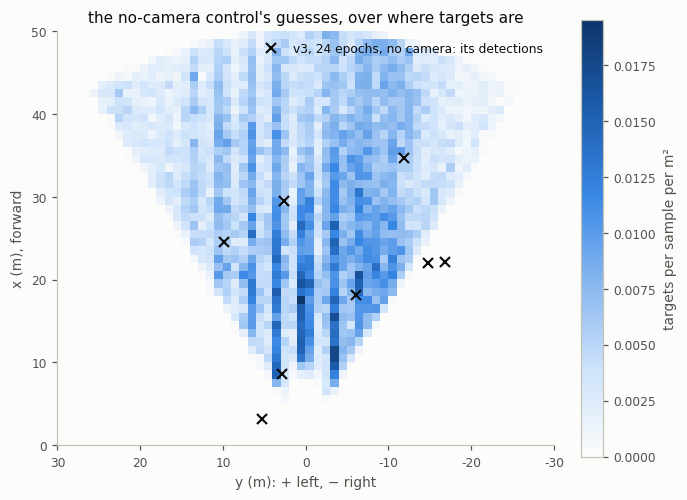

v3, 24 epochs, no camera: 8.1 detections a sample (from 6 to 10)


In [12]:
RAMP = LinearSegmentedColormap.from_list("sequential-blue", ["#fcfcfb", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
if blind_runs:
    b = blind_runs[0]
    det_all = [p["xyz"][p["conf"] >= evaluate.THR, :2] for p in preds[b]]
    tgt_xy = np.concatenate([g["box"][g["mask"], :2] for g in gts])
    h, _, _ = np.histogram2d(-tgt_xy[:, 1], tgt_xy[:, 0], bins=[np.arange(-30, 31, 1.0), np.arange(0, 51, 1.0)])
    fig, ax = plt.subplots(figsize=(6.4, 5.6))
    im_ = ax.imshow(h.T / len(gts), origin="lower", extent=(-30, 30, 0, 50), cmap=RAMP, aspect="equal")
    ax.plot(-det_all[0][:, 1], det_all[0][:, 0], "x", ms=6, mew=1.4, color=views.INK, label=f"{b}: its detections")
    ax.legend(loc="upper right")
    ax.grid(False)
    y_axis_left(ax)
    plt.colorbar(im_, ax=ax, fraction=0.04, label="targets per sample per m²")
    ax.set_title("the no-camera control's guesses, over where targets are")
    plt.show()
    counts_b = np.array([len(d) for d in det_all])
    print(f"{b}: {counts_b.mean():.1f} detections a sample (from {counts_b.min()} to {counts_b.max()})")

**Reading it:**
- **The three seeds agree to 0.006 F1** (0.713–0.720), 0.015 recall and 0.006 causal recall. The 0.01 rule
  of §6.5 sits above that, though by less than the plan assumed: it took the first pass's 0.004.
- **Without the camera the side-car finds almost nothing:** recall 0.057 and precision 0.032 within 30 m at
  its kept epoch (23), and nothing at all until epoch 22. Its 8 guesses (6–10 a sample) are nearly the same
  in every sample: fixed places, some in the two bands where targets are densest, some far outside them.
- **Its training was unhealthy** (section 2): 95% of its steps were clipped, the gradient norm reached
  3 × 10⁶ and the AMP scale fell to 1.5 × 10⁻⁵ after repeated overflows. It still keeps G3 by its letter,
  with 0.12% of steps skipped.
- **The cause is not found.** It is not the LayerNorm on a vanishing input: the projection's bias, the only
  input left, keeps the spread it has in the camera runs (measured on the weights of epochs 1, 3 and 6).
  The first pass's control also found nothing.
- **For the review:** as the baseline of Q1, Q2 and Q10 it says that the image is what finds agents.
  Whether a stably trained control would learn a better prior is open; retraining it in fp32 is one way to
  find out (not done).

## 4. The predictions, drawn

The focus variant at its kept epoch, on select samples drawn at random (seeded, not picked by hand) among
those with 4–20 targets. **On the image:** targets as boxes in their class colour; detections as thin white
boxes. **From above:** targets as outlines, filled when hit; detections as dots, green when they hit a target
of their class within 2 m, red when they are false alarms. The grey lines are the camera's field of view.

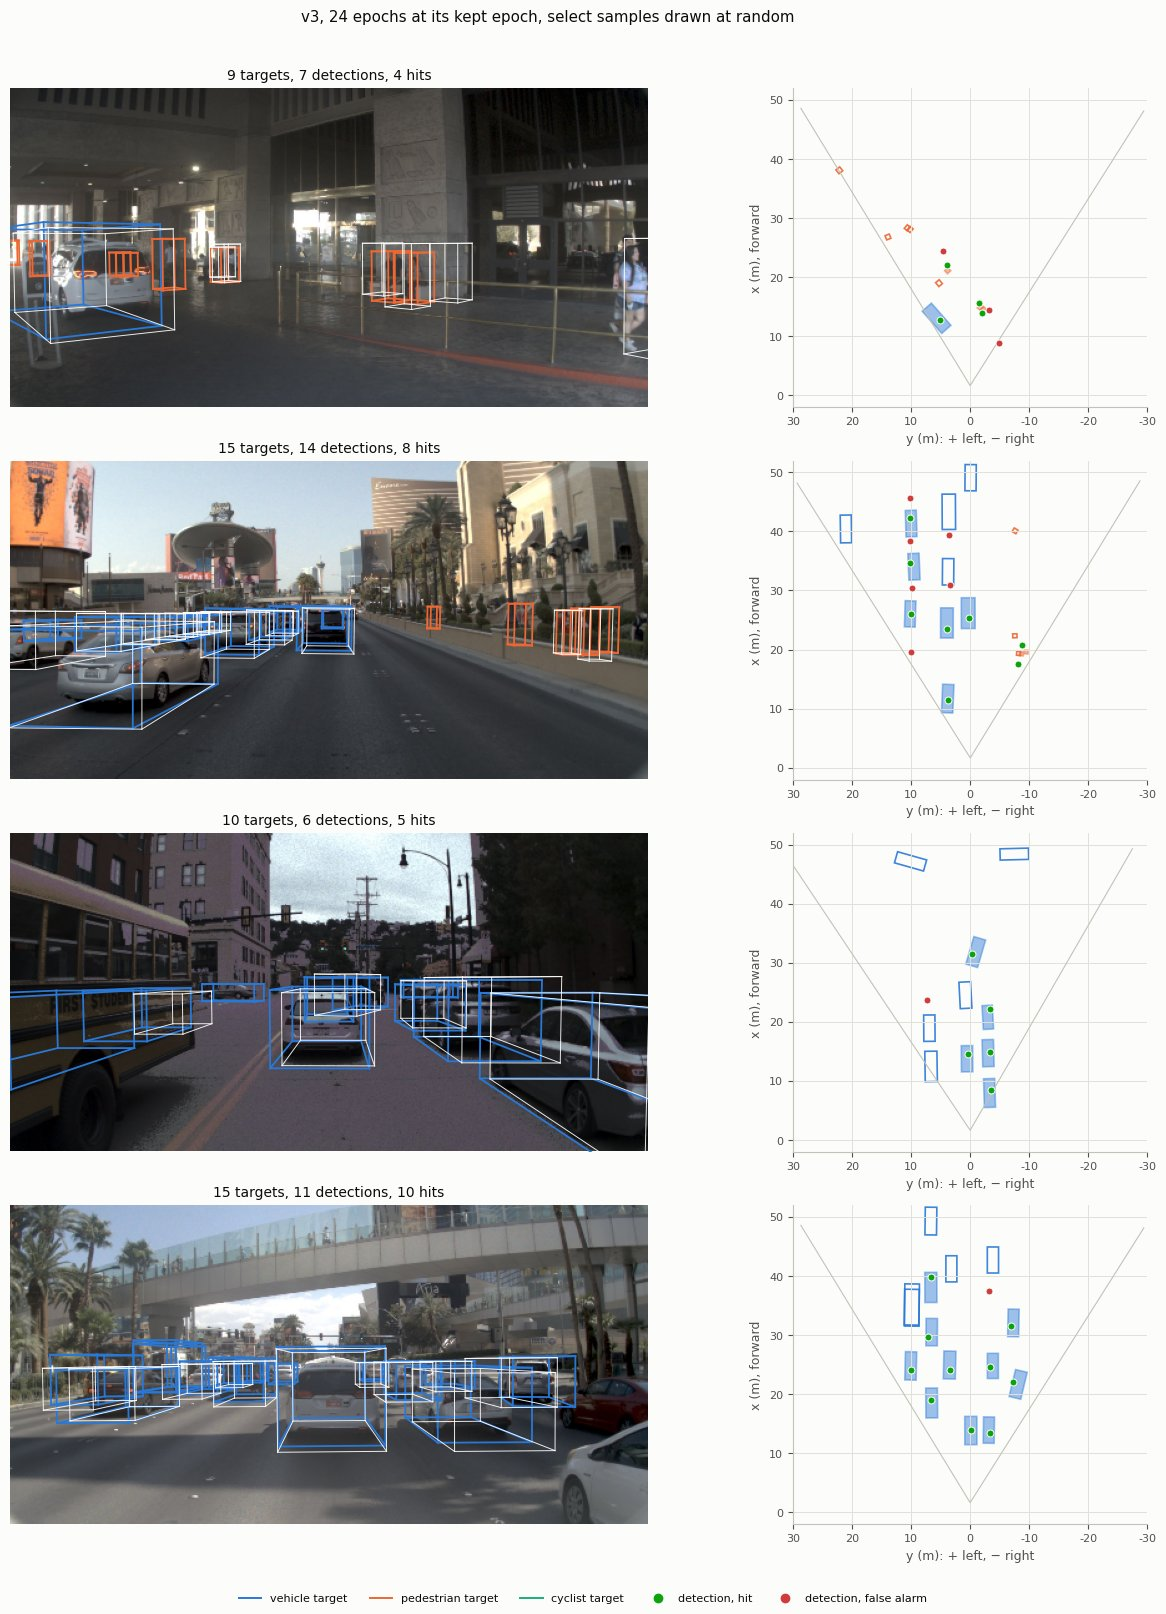

In [13]:
def decoded_boxes(raw, i):
    """Slot boxes in the labels' terms: x, y, z, l, w, h, yaw."""
    b = raw["box"][i]
    return np.c_[b[:, :3], np.exp(b[:, 3:6]), np.arctan2(b[:, 6], b[:, 7])]


def image_of(i):
    r = select[i]
    frame = views.window_frames(NAVSIM, str(token_logs[r]), str(labels["token"][r]))[navsim_data.CURRENT]
    return views.model_view(views.read_image(views.camera_path(NAVSIM, frame)))


def draw_image(ax, name, i, title=True):
    r, gt, pred = select[i], gts[i], preds[name][i]
    m = gt["mask"]
    det, tp, hit = evaluate.match(pred["conf"], pred["cls"], pred["xyz"][:, :2], gt["box"][m, :2], gt["cls"][m])
    ax.imshow(image_of(i))
    for k in np.flatnonzero(m):
        for (u0, v0), (u1, v1) in views.box_edges_2d(proj[r], gt["box"][k][None])[0]:
            ax.plot([u0, u1], [v0, v1], color=views.CLASS_COLOURS[gt["cls"][k]], lw=1.3)
    boxes = decoded_boxes(raws[name][-1], i)
    for q in det:
        for (u0, v0), (u1, v1) in views.box_edges_2d(proj[r], boxes[q][None])[0]:
            ax.plot([u0, u1], [v0, v1], color="white", lw=0.7, alpha=0.9)
    ax.set_xlim(0, 512)
    ax.set_ylim(256, 0)
    ax.axis("off")
    if title:
        n_hit = int(tp.sum())
        ax.set_title(f"{int(m.sum())} targets, {len(det)} detections, {n_hit} hit{'' if n_hit == 1 else 's'}")


def draw_bev(ax, name, i, title=None):
    r, gt, pred = select[i], gts[i], preds[name][i]
    m = gt["mask"]
    det, tp, hit = evaluate.match(pred["conf"], pred["cls"], pred["xyz"][:, :2], gt["box"][m, :2], gt["cls"][m])
    edges = views.view_edges(proj[r], reach=55)
    ax.plot(-edges[[1, 0, 2], 1], edges[[1, 0, 2], 0], color=views.AXIS, lw=0.8)
    for j, k in enumerate(np.flatnonzero(m)):
        outline = views.footprint(gt["box"][k][None])[0]
        colour = views.CLASS_COLOURS[gt["cls"][k]]
        ax.add_patch(Polygon(np.c_[-outline[:, 1], outline[:, 0]], closed=True, ec=colour, lw=1.2,
                             fc=colour if hit[j] >= 0 else "none", alpha=0.9 if hit[j] < 0 else 0.45))
    for q, ok in zip(det, tp):
        ax.plot(-pred["xyz"][q, 1], pred["xyz"][q, 0], "o", ms=5, color=views.HIT if ok else views.MISS,
                mec=views.SURFACE, mew=0.7)
    ax.set_xlim(-30, 30)
    ax.set_ylim(-2, 52)
    ax.set_aspect("equal")
    y_axis_left(ax)
    if title:
        ax.set_title(title)


legend_handles = [plt.Line2D([], [], color=c, lw=1.4, label=f"{n} target") for n, c in zip(views.CLASS_NAMES, views.CLASS_COLOURS)]
legend_handles += [plt.Line2D([], [], marker="o", ls="", color=views.HIT, label="detection, hit"),
                   plt.Line2D([], [], marker="o", ls="", color=views.MISS, label="detection, false alarm")]
rng = np.random.default_rng(4)
shown = [i for i in rng.permutation(len(select)) if 4 <= gts[i]["mask"].sum() <= 20][:4]
fig, axes = plt.subplots(4, 2, figsize=(13, 16), gridspec_kw={"width_ratios": [2.0, 1.0]})
for (ax_img, ax_bev), i in zip(axes, shown):
    draw_image(ax_img, focus, i)
    draw_bev(ax_bev, focus, i)
fig.legend(handles=legend_handles, loc="lower center", ncol=5)
fig.suptitle(f"{focus} at its kept epoch, select samples drawn at random", y=1.0)
plt.tight_layout(rect=(0, 0.02, 1, 0.99))
views.show_jpeg(fig)

**The same samples, every size**, from above (columns: the 5a runs at 12 epochs, then the run looked at
closely):

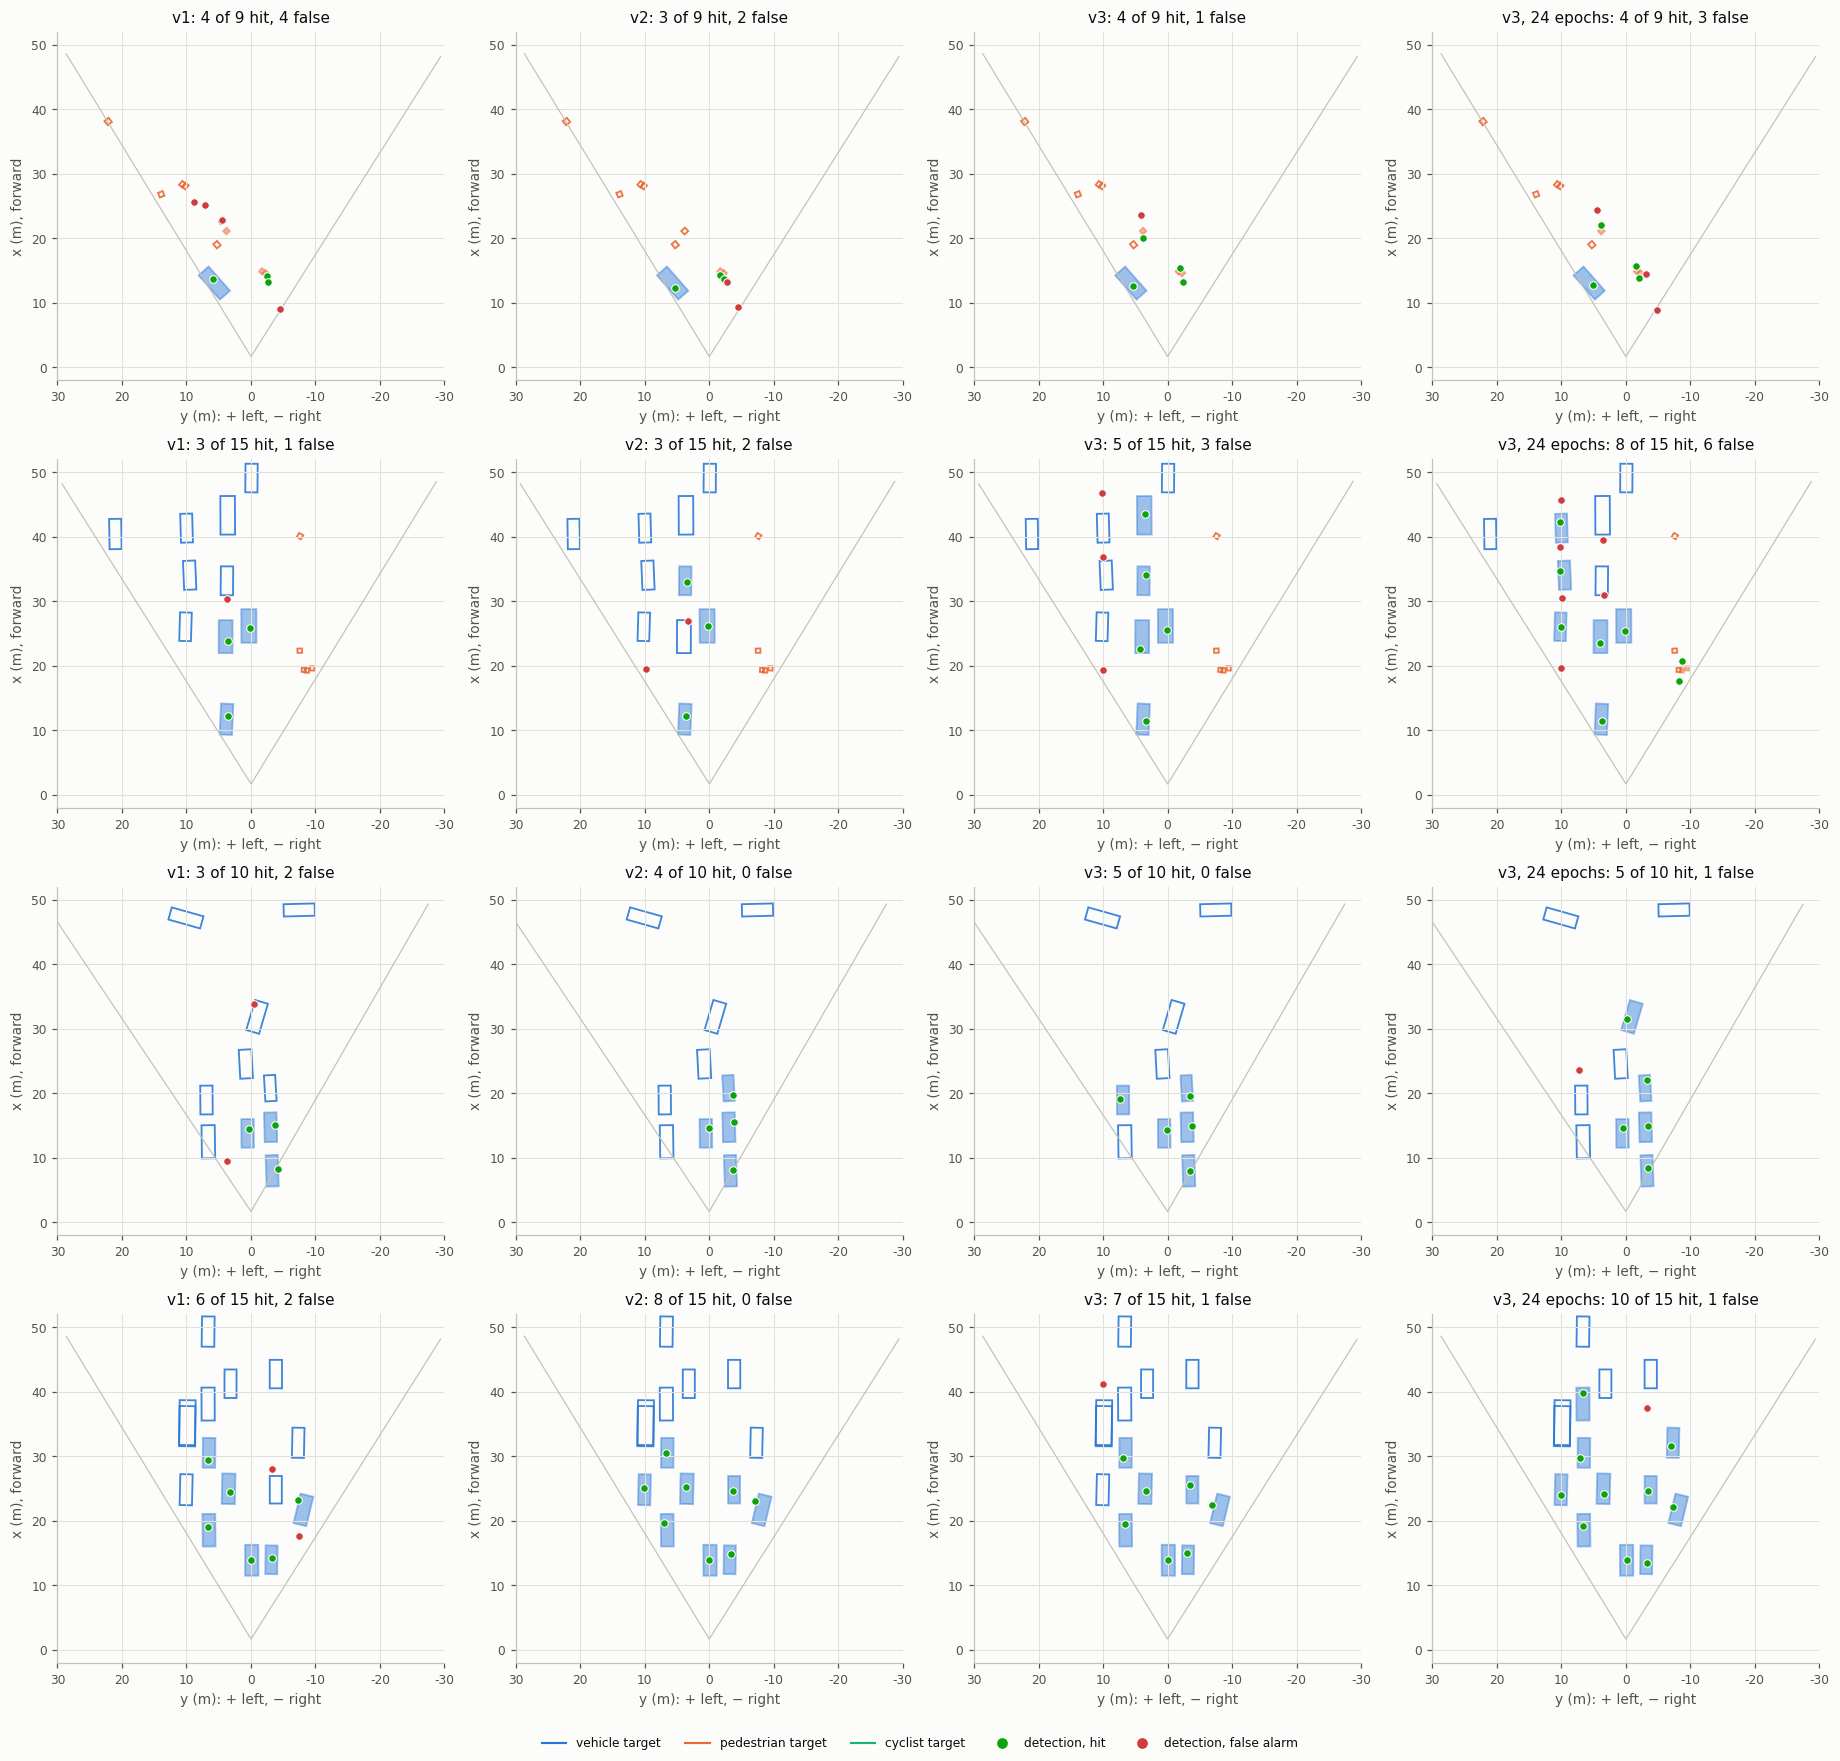

In [14]:
sizes = [v for v in VARIANT_ORDER if v in runs] + ([focus] if focus not in VARIANT_ORDER else [])
fig, axes = plt.subplots(len(shown), len(sizes), figsize=(4.2 * len(sizes), 4.0 * len(shown)), squeeze=False)
for row_axes, i in zip(axes, shown):
    for ax, name in zip(row_axes, sizes):
        m = gts[i]["mask"]
        pred = preds[name][i]
        det, tp, _ = evaluate.match(pred["conf"], pred["cls"], pred["xyz"][:, :2], gts[i]["box"][m, :2], gts[i]["cls"][m])
        draw_bev(ax, name, i, title=f"{name}: {int(tp.sum())} of {int(m.sum())} hit, {len(det) - int(tp.sum())} false")
fig.legend(handles=legend_handles, loc="lower center", ncol=5)
plt.tight_layout(rect=(0, 0.02, 1, 1))
plt.show()

**Where it does worst:** the two select samples where the focus variant misses the most causal targets
(chosen rule), with the camera view and from above:

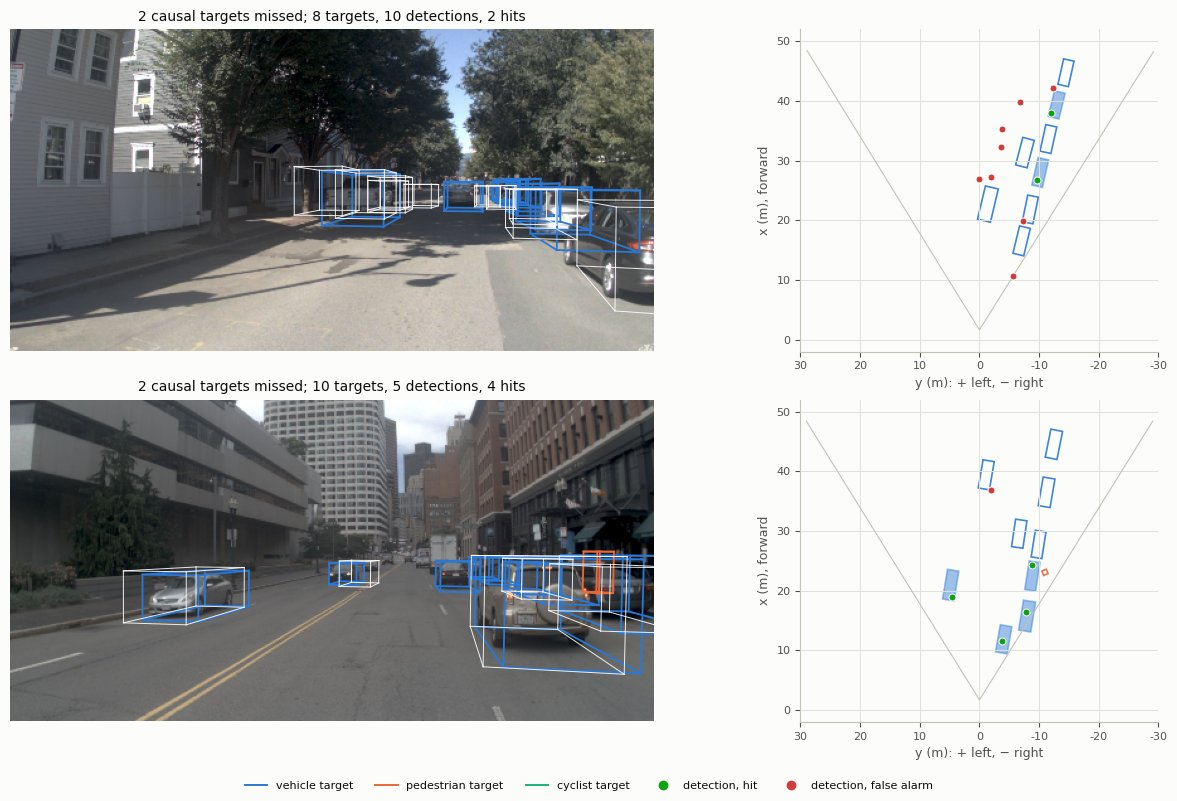

In [15]:
missed_causal = []
for i, (gt, pred) in enumerate(zip(gts, preds[focus])):
    m = gt["mask"]
    _, _, hit = evaluate.match(pred["conf"], pred["cls"], pred["xyz"][:, :2], gt["box"][m, :2], gt["cls"][m])
    missed_causal.append(int((subsets["causal_chosen"][i] & (hit < 0)).sum()))
worst = list(np.argsort(missed_causal, kind="stable")[::-1][:2])
fig, axes = plt.subplots(2, 2, figsize=(13, 8), gridspec_kw={"width_ratios": [2.0, 1.0]})
for (ax_img, ax_bev), i in zip(axes, worst):
    draw_image(ax_img, focus, i)
    ax_img.set_title(f"{missed_causal[i]} causal targets missed; " + ax_img.get_title())
    draw_bev(ax_bev, focus, i)
fig.legend(handles=legend_handles, loc="lower center", ncol=5)
plt.tight_layout(rect=(0, 0.03, 1, 1))
views.show_jpeg(fig)

**Reading it:**
- **These four samples had 1, 2, 2 and 4 hits at epoch 1** (step 3's checkpoint, read with this notebook's
  code); here they have 4, 8, 5 and 10. Near vehicles are found and placed well.
- **What it misses is far or partly hidden:** cars beyond about 35 m, and pedestrians beside and behind
  others, as in the first sample.
- **Its false alarms sit a few metres from real agents,** most along the row of parked cars in the second
  sample: the agent is found but placed too near or too far. Section 7 measures this.
- **The two samples where it misses the most causal targets** are streets lined with parked cars. Several
  detections fall toward the middle of the road, metres from the cars they likely stand for.

## 5. What it misses

Every select target, with what is known about it: class, range, how much of it the camera sees (notebook 01
§8's line-of-sight share), and whether it was hit. Recall by range, in 5 m bins, for every run:

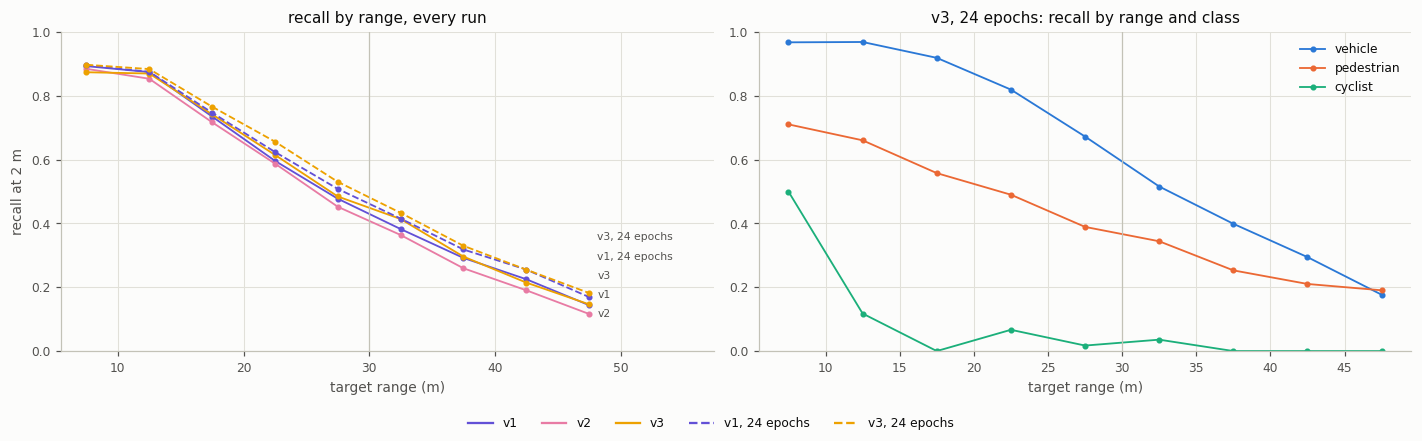

range,"[0, 5)","[5, 10)","[10, 15)","[15, 20)","[20, 25)","[25, 30)","[30, 35)","[35, 40)","[40, 45)","[45, 50)"
v1,NaN,0.893,0.875,0.735,0.597,0.478,0.383,0.292,0.225,0.144
"v1, 24 epochs",NaN,0.896,0.876,0.747,0.624,0.508,0.415,0.318,0.255,0.169
v2,NaN,0.885,0.854,0.717,0.588,0.452,0.364,0.260,0.191,0.116
v3,NaN,0.874,0.870,0.742,0.615,0.485,0.414,0.296,0.215,0.146
"v3, 24 epochs",NaN,0.898,0.884,0.766,0.657,0.531,0.433,0.330,0.255,0.182
"v3, 24 epochs, seed 1",NaN,0.896,0.869,0.766,0.636,0.535,0.445,0.330,0.254,0.175
"v3, 24 epochs, seed 2",NaN,0.904,0.880,0.755,0.629,0.518,0.436,0.331,0.256,0.191
"v3, 24 epochs, no camera",NaN,0.301,0.037,0.042,0.038,0.069,0.031,0.029,0.004,0.000


In [16]:
def target_table(name):
    rows_ = []
    for i, (gt, pred) in enumerate(zip(gts, preds[name])):
        m = gt["mask"]
        det, tp, hit = evaluate.match(pred["conf"], pred["cls"], pred["xyz"][:, :2], gt["box"][m, :2], gt["cls"][m])
        shown_ = pred["conf"] >= evaluate.THR
        for j, k in enumerate(np.flatnonzero(m)):
            same = shown_ & (pred["cls"] == gt["cls"][k])
            d_same = np.hypot(*(pred["xyz"][same, :2] - gt["box"][k, :2]).T) if same.any() else np.array([np.inf])
            rows_.append((i, sample_log[i], int(gt["cls"][k]), float(np.hypot(*gt["box"][k, :2])), hit[j] >= 0,
                          float(d_same.min()), bool(subsets["visible"][i][j]), bool(subsets["causal_chosen"][i][j])))
    return pd.DataFrame(rows_, columns=["sample", "log", "cls", "range", "hit", "nearest same-class detection (m)",
                                        "visible", "causal"])


targets_df = {name: target_table(name) for name in runs}
bins_5 = np.arange(0, 55, 5)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.0))
ends = []
for name in compare:
    t = targets_df[name]
    b = pd.cut(t["range"], bins_5, right=False)
    rec = t.groupby(b).hit.mean()
    x = bins_5[:-1] + 2.5
    axes[0].plot(x, rec.values, marker="o", ms=3, lw=1.2, **style(name))
    ends.append((name, x[-1], rec.values[-1]))
axes[0].set_xlabel("target range (m)")
axes[0].set_ylabel("recall at 2 m")
axes[0].set_ylim(0, 1)
axes[0].axvline(30, color=views.AXIS, lw=0.8)
axes[0].set_title("recall by range, every run")
label_ends(axes[0], ends)
t = targets_df[focus]
for c, cname in enumerate(views.CLASS_NAMES):
    tc = t[t.cls == c]
    rec = tc.groupby(pd.cut(tc["range"], bins_5, right=False)).hit.mean()
    axes[1].plot(bins_5[:-1] + 2.5, rec.values, marker="o", ms=3, lw=1.2, color=views.CLASS_COLOURS[c], label=cname)
axes[1].set_xlabel("target range (m)")
axes[1].set_ylim(0, 1)
axes[1].axvline(30, color=views.AXIS, lw=0.8)
axes[1].set_title(f"{focus}: recall by range and class")
axes[1].legend(loc="upper right")
fig.legend(handles=legend_for(compare), loc="lower center", ncol=len(compare))
plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()
pd.DataFrame({name: t.groupby(pd.cut(t["range"], bins_5, right=False)).hit.mean() for name, t in targets_df.items()}).T.round(3)

**Recall by how much of the target the camera sees** (notebook 01 §8's line-of-sight share: the part of its
box on the image that no nearer agent's box covers), every run:

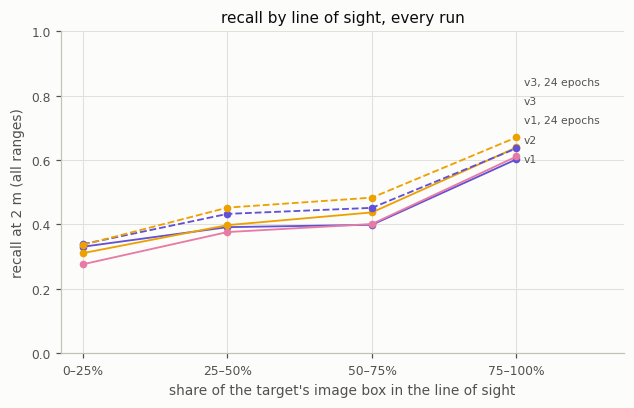

,0–25%,25–50%,50–75%,75–100%
targets,14513.000,4318.000,3244.000,10300.000
v1,0.331,0.392,0.399,0.603
v2,0.276,0.376,0.401,0.611
v3,0.311,0.398,0.437,0.639
"v1, 24 epochs",0.339,0.433,0.452,0.637
"v3, 24 epochs",0.337,0.452,0.483,0.671


In [17]:
seen_share = [np.nan_to_num(im.visibility(proj[r], navsim_data.agents_of(labels, r)["box"])[
    tg.target_index(navsim_data.agents_of(labels, r), proj[r])], nan=0.0) for r in select]
share_all = np.concatenate(seen_share)
share_bins = [0, 0.25, 0.5, 0.75, 1.01]
share_labels = ["0–25%", "25–50%", "50–75%", "75–100%"]
fig, ax = plt.subplots(figsize=(6.6, 3.8))
ends = []
by_share = {}
for name in compare:
    t = targets_df[name]
    rec = t.hit.groupby(pd.cut(share_all, share_bins, right=False)).mean()
    by_share[name] = rec.values
    ax.plot(range(4), rec.values, marker="o", ms=4, lw=1.2, **style(name))
    ends.append((name, 3, rec.values[-1]))
ax.set_xticks(range(4))
ax.set_xticklabels(share_labels)
ax.set_xlabel("share of the target's image box in the line of sight")
ax.set_ylabel("recall at 2 m (all ranges)")
ax.set_ylim(0, 1)
ax.set_title("recall by line of sight, every run")
label_ends(ax, ends)
plt.show()
pd.concat([pd.DataFrame([np.histogram(share_all, share_bins)[0]], index=["targets"], columns=share_labels),
           pd.DataFrame(by_share, index=share_labels).T.round(3)])

**What each target is detected as**, for the run looked at closely: the class of the most confident
detection within 2 m of it, of any class, or none. A cyclist found as a pedestrian is not a hit, since
the readout matches within a class.

In [18]:
confusion = np.zeros((tg.NUM_CLASSES, tg.NUM_CLASSES + 1), int)
for gt, pred in zip(gts, preds[focus]):
    m = gt["mask"]
    shown_ = np.flatnonzero(pred["conf"] >= evaluate.THR)
    shown_ = shown_[np.argsort(-pred["conf"][shown_], kind="stable")]
    for k in np.flatnonzero(m):
        d = np.hypot(*(pred["xyz"][shown_, :2] - gt["box"][k, :2]).T) if len(shown_) else np.zeros(0)
        near = shown_[d <= evaluate.HIT_M]
        confusion[gt["cls"][k], pred["cls"][near[0]] if len(near) else tg.NUM_CLASSES] += 1
pd.DataFrame(confusion / confusion.sum(1, keepdims=True), index=[f"{c} target" for c in views.CLASS_NAMES],
             columns=[f"as {c}" for c in views.CLASS_NAMES] + ["nothing within 2 m"]).round(3).assign(
    targets=confusion.sum(1))

,as vehicle,as pedestrian,as cyclist,nothing within 2 m,targets
vehicle target,0.580,0.002,0.000,0.418,17912
pedestrian target,0.011,0.478,0.000,0.511,14251
cyclist target,0.005,0.184,0.038,0.774,212


**Why a target is missed.** For the focus variant's misses: is there a detection of its class nearby (the
agent was found but placed too far, beyond 2 m), or none (the agent was not found at all)? And is it in the
line of sight?

In [19]:
t = targets_df[focus]
miss = t[~t.hit]
kinds = pd.cut(miss["nearest same-class detection (m)"], [0, 4, 8, np.inf], right=False,
               labels=["a detection of its class 2–4 m away", "one 4–8 m away", "none within 8 m"])
table = pd.crosstab(kinds, np.where(miss.visible, "visible", "hidden"), normalize="all").round(3)
table["all misses"] = table.sum(1)
print(f"{focus}: {len(miss):,} misses of {len(t):,} targets; their share by kind:")
table

v3, 24 epochs: 17,062 misses of 32,375 targets; their share by kind:


col_0,hidden,visible,all misses
nearest same-class detection (m),,,
a detection of its class 2–4 m away,0.308,0.122,0.430
one 4–8 m away,0.192,0.047,0.239
none within 8 m,0.236,0.095,0.331


**Reading it:**
- **Recall falls steadily with range.** For v3 on 24 epochs it is 0.90 at 5–10 m, 0.77 at 15–20 m, 0.53 at
  25–30 m, 0.33 at 35–40 m and 0.18 at 45–50 m. The 24-epoch schedule lifts it at every range.
- **What the camera cannot see, it rarely finds:** recall is 0.34 for targets at most a quarter visible
  (14,513 of them) and 0.67 for those at least three quarters visible (10,300).
- **Classes are seldom confused, and cyclists are seldom found.** 0.3% of detections are of the wrong class
  (section 6). A cyclist is found as a cyclist 4% of the time, as a pedestrian 18%, and not at all 77%;
  there are 212 cyclists among the select logs' 32,375 targets.
- **Most misses are agents found but misplaced:** of the misses of v3 on 24 epochs, 43% have a detection of
  their class 2–4 m away and 24% one 4–8 m away; 33% have none within 8 m. Three quarters of the misses
  are hidden agents (less than half of their box in the line of sight).

## 6. What it gets wrong: the false alarms

Every detection that hits no target, sorted into the first kind that fits:
1. **duplicate**: another detection of its class, more confident, within 2 m of it;
2. **wrong class**: a target of another class within 2 m;
3. **mislocated**: a target of its own class 2–4 m away;
4. **a labelled agent that is not a target**: within 2 m of a labelled agent the targets leave out (other
   classes such as barriers and cones, agents beyond 50 m, or ones whose centre is outside the image);
5. **nothing labelled nearby**: none of these. Some may be real agents the labels miss.

In [20]:
FP_KINDS = ("duplicate", "wrong class", "mislocated (2–4 m)", "a labelled non-target", "nothing labelled nearby")


def false_alarms(name):
    out = []
    for i, (gt, pred) in enumerate(zip(gts, preds[name])):
        r = select[i]
        m = gt["mask"]
        det, tp, hit = evaluate.match(pred["conf"], pred["cls"], pred["xyz"][:, :2], gt["box"][m, :2], gt["cls"][m])
        agents = navsim_data.agents_of(labels, r)
        others = np.setdiff1d(np.arange(len(agents["box"])), tg.target_index(agents, proj[r]))
        oxy = np.asarray(agents["box"], dtype=np.float64)[others, :2]
        gxy, gcls = gt["box"][m, :2].astype(np.float64), gt["cls"][m]
        for k, q in enumerate(det):
            if tp[k]:
                continue
            xy, c = pred["xyz"][q, :2], pred["cls"][q]
            earlier = det[:k][pred["cls"][det[:k]] == c]  # det is sorted by confidence
            if len(earlier) and np.hypot(*(pred["xyz"][earlier, :2] - xy).T).min() <= evaluate.HIT_M:
                kind = FP_KINDS[0]
            elif len(gxy) and (np.hypot(*(gxy[gcls != c] - xy).T) <= evaluate.HIT_M).any():
                kind = FP_KINDS[1]
            elif len(gxy) and (np.hypot(*(gxy[gcls == c] - xy).T) <= 2 * evaluate.HIT_M).any():
                kind = FP_KINDS[2]
            elif len(oxy) and (np.hypot(*(oxy - xy).T) <= evaluate.HIT_M).any():
                kind = FP_KINDS[3]
            else:
                kind = FP_KINDS[4]
            out.append((i, int(c), float(np.hypot(*xy)), float(pred["conf"][q]), kind))
    return pd.DataFrame(out, columns=["sample", "cls", "range", "conf", "kind"])


fp = {name: false_alarms(name) for name in runs}
n_det = {name: int(sum((p["conf"] >= evaluate.THR).sum() for p in preds[name])) for name in runs}
table = pd.DataFrame({name: f.kind.value_counts().reindex(FP_KINDS).fillna(0) / n_det[name] for name, f in fp.items()})
table.loc["all false alarms"] = table.sum()
print("share of all detections (any range), by kind of false alarm:")
table.round(3)

share of all detections (any range), by kind of false alarm:


,v1,"v1, 24 epochs",v2,v3,"v3, 24 epochs","v3, 24 epochs, seed 1","v3, 24 epochs, seed 2","v3, 24 epochs, no camera"
kind,,,,,,,,
duplicate,0.148,0.129,0.120,0.109,0.117,0.119,0.123,0.011
wrong class,0.003,0.003,0.003,0.004,0.003,0.003,0.004,0.016
mislocated (2–4 m),0.180,0.172,0.159,0.163,0.156,0.151,0.146,0.075
a labelled non-target,0.011,0.009,0.009,0.009,0.010,0.010,0.011,0.043
nothing labelled nearby,0.061,0.056,0.041,0.050,0.058,0.053,0.060,0.824
all false alarms,0.403,0.369,0.332,0.335,0.344,0.337,0.345,0.969


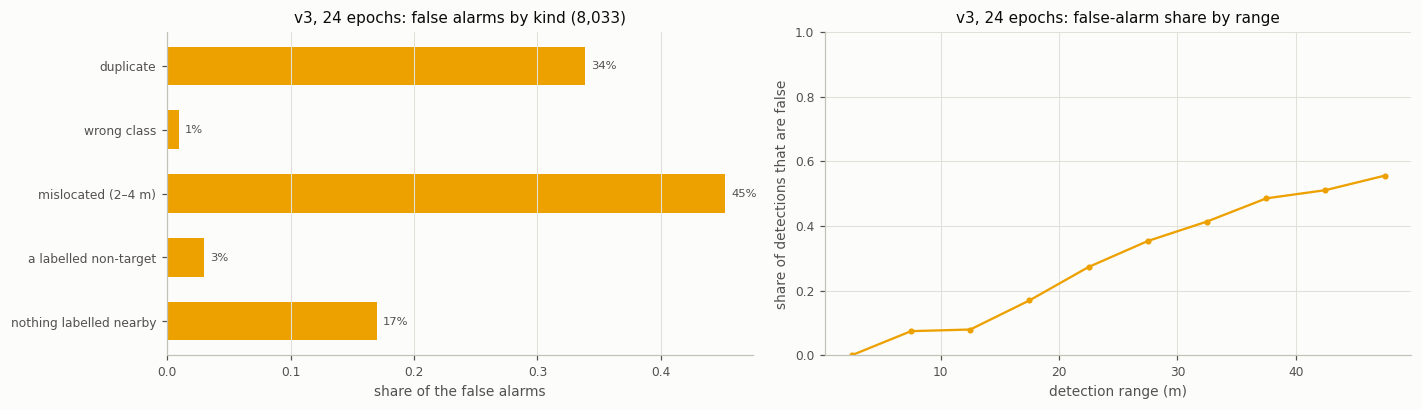

In [21]:
f = fp[focus]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
share = f.kind.value_counts().reindex(FP_KINDS).fillna(0) / len(f)
axes[0].barh(range(len(FP_KINDS))[::-1], share.values, color=VARIANT_COLOURS[runs[focus]["args"]["variant"]], height=0.6)
axes[0].set_yticks(range(len(FP_KINDS))[::-1])
axes[0].set_yticklabels(FP_KINDS)
for y_, v in zip(range(len(FP_KINDS))[::-1], share.values):
    axes[0].text(v + 0.005, y_, f"{v:.0%}", va="center", fontsize=7.5, color=views.INK_2)
axes[0].set_xlabel("share of the false alarms")
axes[0].set_title(f"{focus}: false alarms by kind ({len(f):,})")
axes[0].grid(axis="y", visible=False)
all_det = np.concatenate([np.hypot(p["xyz"][p["conf"] >= evaluate.THR, 0], p["xyz"][p["conf"] >= evaluate.THR, 1])
                          for p in preds[focus]])
fp_counts, det_counts = np.histogram(f["range"], bins_5)[0], np.histogram(all_det, bins_5)[0]
axes[1].plot(bins_5[:-1] + 2.5, fp_counts / np.maximum(det_counts, 1), marker="o", ms=3,
             color=VARIANT_COLOURS[runs[focus]["args"]["variant"]])
axes[1].set_ylim(0, 1)
axes[1].set_xlabel("detection range (m)")
axes[1].set_ylabel("share of detections that are false")
axes[1].set_title(f"{focus}: false-alarm share by range")
plt.tight_layout()
plt.show()

**Reading it:**
- **A third of the detections hit nothing** (34% for v3 on 24 epochs, 40% for v1), and most of these sit
  beside a real agent: 45% of the false alarms are 2–4 m from a target of their class (mislocated), 34% a
  second, less confident detection beside another of their class (duplicates).
- **Few are inventions:** 17% of the false alarms fit none of the other kinds, 6% of all detections. Some
  of those may be agents the labels miss.
- **Wrong class is rare** (1% of the false alarms), and so are detections on labelled agents that are not
  targets (3%).
- **False alarms grow with range,** from about 7% of the detections at 5–10 m to 27% at 20–25 m and 56% at
  45–50 m: the misses' distance problem, seen from the other side.

## 7. Where its boxes go wrong: depth, not direction

Plan §4.1 argued that one camera fixes an agent's **direction** well and its **distance** poorly: beyond 20 m
an agent spans one or two token rows. Here that is measured. Each target is paired with the nearest
detection of its class within 5 m (greedy by confidence, as the readout pairs at 2 m), and the centre error
is split along the camera's ray (depth: positive means placed too far) and across it (direction).

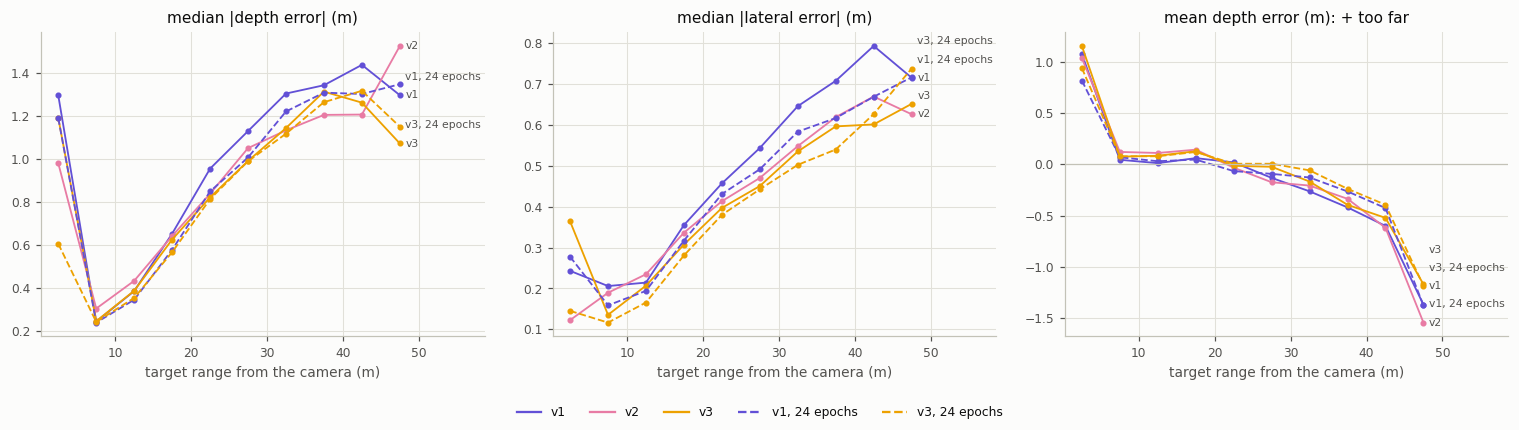

,pairs within 5 m,median |depth| (m),median |lateral| (m),median |direction| (°),share with |depth| > 2 m
"v3, 24 epochs, target range (m)",,,,,
"[0, 10)",947,0.243,0.117,0.798,0.013
"[10, 20)",5068,0.465,0.223,0.849,0.077
"[20, 30)",6259,0.885,0.404,0.947,0.189
"[30, 50)",6888,1.200,0.554,0.857,0.299


In [22]:
def camera_centre(P):
    """The ego-frame point the projection maps to the camera's own centre."""
    return -np.linalg.solve(P[:3, :3].astype(np.float64), P[:3, 3].astype(np.float64))


def ray_errors(name, radius=5.0):
    rows_ = []
    for i, (gt, pred) in enumerate(zip(gts, preds[name])):
        m = gt["mask"]
        gxy = gt["box"][m, :2].astype(np.float64)
        _, _, pair = evaluate.match(pred["conf"], pred["cls"], pred["xyz"][:, :2], gxy, gt["cls"][m], radius=radius)
        c = camera_centre(P_SEL[i])[:2]
        for j in np.flatnonzero(pair >= 0):
            g, d = gxy[j], pred["xyz"][pair[j], :2].astype(np.float64)
            ray = (g - c) / np.linalg.norm(g - c)
            err = d - g
            along, across = float(err @ ray), float(ray[0] * err[1] - ray[1] * err[0])
            rows_.append((float(np.linalg.norm(g - c)), int(gt["cls"][m][j]), along, across,
                          math.degrees(math.atan2(across, np.linalg.norm(g - c)))))
    return pd.DataFrame(rows_, columns=["range", "cls", "depth error (m)", "lateral error (m)", "direction error (°)"])


errs = {name: ray_errors(name) for name in compare}
fig, axes = plt.subplots(1, 3, figsize=(14, 3.9))
for ax, (col, title) in zip(axes, [("depth error (m)", "median |depth error| (m)"), ("lateral error (m)", "median |lateral error| (m)"),
                                   ("depth error (m)", "mean depth error (m): + too far")]):
    ends = []
    for name, e in errs.items():
        g = e.groupby(pd.cut(e["range"], bins_5, right=False))[col]
        y = (g.mean() if "mean" in title else g.apply(lambda s: s.abs().median())).values
        ax.plot(bins_5[:-1] + 2.5, y, marker="o", ms=3, lw=1.2, **style(name))
        ends.append((name, 47.5, y[-1]))
    if "mean" in title:
        ax.axhline(0, color=views.AXIS, lw=0.8)
    ax.set_xlabel("target range from the camera (m)")
    ax.set_title(title)
    label_ends(ax, ends)
fig.legend(handles=legend_for(compare), loc="lower center", ncol=len(compare))
plt.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()
e = errs[focus]
pd.DataFrame({
    "pairs within 5 m": e.groupby(pd.cut(e["range"], [0, 10, 20, 30, 50], right=False)).size(),
    "median |depth| (m)": e.groupby(pd.cut(e["range"], [0, 10, 20, 30, 50], right=False))["depth error (m)"].apply(lambda s: s.abs().median()),
    "median |lateral| (m)": e.groupby(pd.cut(e["range"], [0, 10, 20, 30, 50], right=False))["lateral error (m)"].apply(lambda s: s.abs().median()),
    "median |direction| (°)": e.groupby(pd.cut(e["range"], [0, 10, 20, 30, 50], right=False))["direction error (°)"].apply(lambda s: s.abs().median()),
    "share with |depth| > 2 m": e.groupby(pd.cut(e["range"], [0, 10, 20, 30, 50], right=False))["depth error (m)"].apply(lambda s: (s.abs() > 2).mean()),
}).rename_axis(f"{focus}, target range (m)")

**Reading it:**
- **The direction is right to under a degree at every range** (median 0.80–0.95° for v3 on 24 epochs). The
  lateral error grows with range only as an angle does: 0.12 m within 10 m, 0.55 m at 30–50 m.
- **The distance is what goes wrong.** The median depth error grows from 0.24 m within 10 m to 0.47 m at
  10–20 m, 0.89 m at 20–30 m and 1.20 m at 30–50 m. Beyond 30 m, 30% of agents are placed more than 2 m off
  in depth, past the readout's hit radius, whatever their direction.
- **Far agents are placed too near:** the mean depth error is near zero from 5 to 30 m, then about −0.25 m
  at 35–40 m, −0.4 m at 40–45 m and −1.2 m at 45–50 m. Agents within 5 m of the camera are placed about
  1 m too far (probably because the image's lower edge cuts them: *argued*).
- **Size and schedule barely change it:** the five runs' depth curves lie within about 0.2 m of each other
  out to 45 m. Plan §4.1 argued this from the tokens (beyond 20 m an agent spans a token row or two); this
  is the measurement.

## 8. Motion: velocity and the 1 s path

The side-car sees two frames 0.5 s apart and must give each agent's velocity over the ground, without
being told how fast the ego moves (plan §3.2). If it confused its own motion with the agents', a parked car
would seem to move at the ego's speed. **Velocity error of the hits, by the ego's speed**, for agents that
stand still and agents that move:

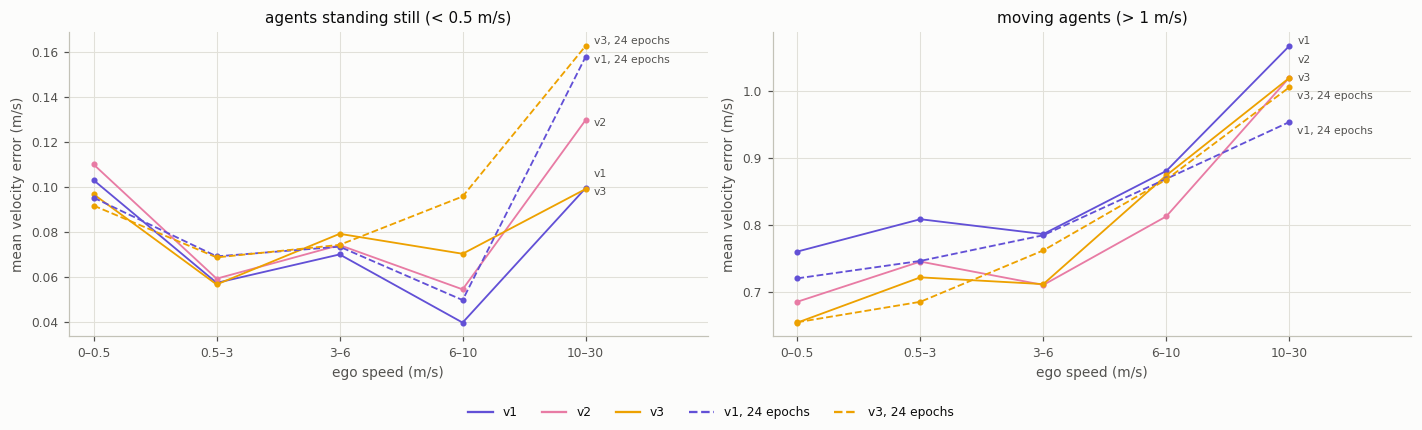

,agents standing still (hits),mean error (m/s),median error (m/s),share given more than 0.5 m/s
"v3, 24 epochs, ego speed (m/s)",,,,
"[0.0, 0.5)",664,0.092,0.000,0.045
"[0.5, 3.0)",2514,0.069,0.000,0.041
"[3.0, 6.0)",2704,0.074,0.000,0.049
"[6.0, 10.0)",1170,0.096,0.000,0.057
"[10.0, 30.0)",302,0.163,0.016,0.109


In [23]:
def motion_table(name):
    rows_ = []
    for i, (gt, pred) in enumerate(zip(gts, preds[name])):
        m = gt["mask"]
        _, _, hit = evaluate.match(pred["conf"], pred["cls"], pred["xyz"][:, :2], gt["box"][m, :2], gt["cls"][m])
        for j in np.flatnonzero(hit >= 0):
            k, q = np.flatnonzero(m)[j], hit[j]
            v_true = gt["vel"][k].astype(np.float64)
            ok = bool(gt["path_ok"][k, 1])
            rows_.append({
                "ego speed": ego_speed[i], "speed": float(np.hypot(*v_true)),
                "velocity error (m/s)": float(np.hypot(*(pred["vel"][q] - v_true))),
                "displacement error at 1 s (m)": float(np.hypot(*(raws[name][-1]["path"][i, q, 1] - gt["path"][k, 1]))) if ok else np.nan,
                "constant velocity, its own (m)": float(np.hypot(*(pred["vel"][q] * 1.0 - gt["path"][k, 1]))) if ok else np.nan,
            })
    return pd.DataFrame(rows_)


motion = {name: motion_table(name) for name in compare}
ego_bins = [0, 0.5, 3, 6, 10, 30]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.9))
for ax, (title, moving) in zip(axes, [("agents standing still (< 0.5 m/s)", False), ("moving agents (> 1 m/s)", True)]):
    ends = []
    for name, mt in motion.items():
        sel = mt[mt.speed > evaluate.MOVING_MPS] if moving else mt[mt.speed < 0.5]
        g = sel.groupby(pd.cut(sel["ego speed"], ego_bins, right=False))["velocity error (m/s)"].mean()
        x = np.arange(len(g))
        ax.plot(x, g.values, marker="o", ms=3, lw=1.2, **style(name))
        ends.append((name, x[-1], g.values[-1]))
    ax.set_xticks(range(len(ego_bins) - 1))
    ax.set_xticklabels([f"{a:g}–{b:g}" for a, b in zip(ego_bins[:-1], ego_bins[1:])])
    ax.set_xlabel("ego speed (m/s)")
    ax.set_ylabel("mean velocity error (m/s)")
    ax.set_title(title)
    label_ends(ax, ends)
fig.legend(handles=legend_for(compare), loc="lower center", ncol=len(compare))
plt.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()
mt = motion[focus]
still = mt[mt.speed < 0.5]
g = still.groupby(pd.cut(still["ego speed"], ego_bins, right=False))["velocity error (m/s)"]
pd.DataFrame({"agents standing still (hits)": g.size(), "mean error (m/s)": g.mean(), "median error (m/s)": g.median(),
              "share given more than 0.5 m/s": g.apply(lambda v: (v > 0.5).mean())}).rename_axis(f"{focus}, ego speed (m/s)")

**The 1 s path of moving agents** against constant velocity (Q4's comparison, here on select). FDE is where
the path ends against where the agent was at +1 s; the displacement error removes the position error,
comparing only the motion from each centre (notebook 04 §4b):

In [24]:
path_rows = {}
for name in compare:
    r, mt = reads[name], motion[name]
    mv = mt[mt.speed > evaluate.MOVING_MPS]
    path_rows[name] = {
        "moving hits with a full path": r["path_hits_moving"],
        "FDE at 1 s: the side-car's path (m)": r["path_fde_1s_model_moving"],
        "FDE: constant velocity, its own velocity (m)": r["path_fde_1s_cv_pred_moving"],
        "FDE: standing still (m)": r["path_fde_1s_stationary_moving"],
        "FDE: constant velocity, the label's velocity (m)": r["path_fde_1s_cv_label_moving"],
        "path against its own constant velocity": f"{100 * (r['path_fde_1s_model_moving'] / r['path_fde_1s_cv_pred_moving'] - 1):+.1f}%",
        "displacement error at 1 s, the side-car (m)": mv["displacement error at 1 s (m)"].mean(),
        "displacement error, its own constant velocity (m)": mv["constant velocity, its own (m)"].mean(),
    }
pd.DataFrame(path_rows)

,v1,v2,v3,"v1, 24 epochs","v3, 24 epochs"
moving hits with a full path,6362,6110,6415,6627,6767
FDE at 1 s: the side-car's path (m),1.286,1.24,1.243,1.255,1.232
"FDE: constant velocity, its own velocity (m)",1.348,1.295,1.301,1.321,1.294
FDE: standing still (m),3.975,4.116,4.181,4.078,4.228
"FDE: constant velocity, the label's velocity (m)",0.368,0.381,0.385,0.379,0.387
path against its own constant velocity,-4.6%,-4.3%,-4.5%,-5.0%,-4.8%
"displacement error at 1 s, the side-car (m)",0.873,0.815,0.82,0.847,0.82
"displacement error, its own constant velocity (m)",0.95,0.892,0.902,0.932,0.905


**Reading it:**
- **The ego's own motion does not leak into the agents':** an agent standing still gets a mean velocity
  error of 0.07–0.10 m/s at ego speeds up to 10 m/s (0.16 m/s above), and 4–6% of them are given more than
  0.5 m/s (11% above 10 m/s). The side-car infers ground velocity from two frames without being told the
  ego's speed.
- **Moving agents' velocity error grows with the ego's speed,** from 0.65 m/s when the ego is stopped to
  1.0 m/s above 10 m/s (v3 on 24 epochs). Faster traffic has larger velocities to get wrong (*argued*).
- **The 1 s path beats constant velocity from its own velocity by 4–5% in every run** (v3 on 24 epochs:
  1.232 against 1.294 m), within Q4's predicted 3–8%. Without the position error the gain is larger: a
  displacement error of 0.82 against 0.91 m (9%).
- **Most of the path's error is where the agent is and how fast it goes, not the path's shape:** constant
  velocity from the label's own centre and velocity ends 0.39 m from the truth.

## 9. Confidence: ranking and calibration

**Average precision** (notebook 04 §4a's prototype): every slot of a class sorted by confidence, matched
greedily at 2 m, precision averaged over 101 recall points, within 30 m. It does not depend on the 0.5
threshold. **Calibration** (04 §4c): every slot of confidence at least 0.1, matched greedily, binned by
confidence: does 0.7 mean seven in ten are right?

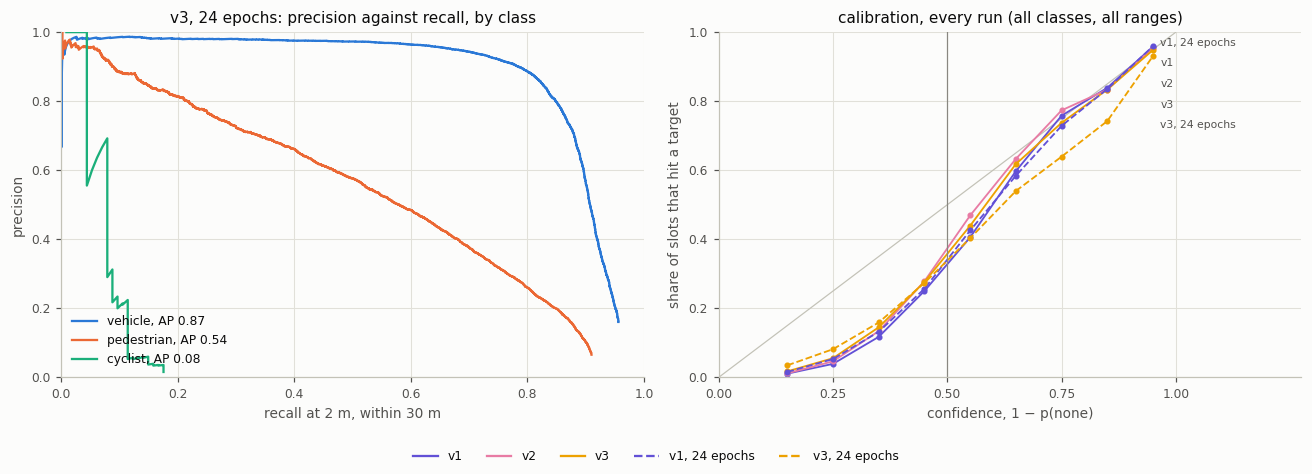

,v1,v2,v3,"v1, 24 epochs","v3, 24 epochs","v3, 24 epochs, seed 1","v3, 24 epochs, seed 2","v3, 24 epochs, no camera"
"AP at 2 m, vehicles",0.813,0.830,0.842,0.838,0.869,0.877,0.870,0.010
"AP at 2 m, pedestrians",0.480,0.512,0.531,0.493,0.535,0.529,0.536,0.000
"AP at 2 m, cyclists",0.108,0.062,0.064,0.039,0.083,0.078,0.071,0.000
mean AP at 2 m,0.467,0.468,0.479,0.457,0.496,0.495,0.493,0.003


In [25]:
def softmax(logits):
    e_ = np.exp(logits - logits.max(-1, keepdims=True))
    return e_ / e_.sum(-1, keepdims=True)


def conf_cls(raw):
    p = softmax(raw["logits"])
    return 1.0 - p[..., tg.NONE], p[..., : tg.NONE].argmax(-1)


def average_precision(raw, cls_k, radius=2.0, max_range=30.0, floor=0.01):
    conf_all, cls_all = conf_cls(raw)
    dets, gt_xy = [], []
    for i, gt in enumerate(gts):
        m = gt["mask"] & (gt["cls"] == cls_k)
        g = gt["box"][m, :2]
        gt_xy.append(g[np.hypot(g[:, 0], g[:, 1]) < max_range])
        sel = (cls_all[i] == cls_k) & (conf_all[i] >= floor)
        p = raw["box"][i, sel, :2]
        near = np.hypot(p[:, 0], p[:, 1]) < max_range
        dets += [(c, i, xy_) for c, xy_ in zip(conf_all[i, sel][near], p[near])]
    n_gt = sum(len(g) for g in gt_xy)
    dets.sort(key=lambda d: -d[0])
    used = [np.zeros(len(g), bool) for g in gt_xy]
    tp = np.zeros(len(dets))
    for k, (_, i, xy_) in enumerate(dets):
        if not len(gt_xy[i]):
            continue
        d = np.hypot(*(gt_xy[i] - xy_).T)
        d[used[i]] = np.inf
        g = int(np.argmin(d))
        if d[g] <= radius:
            used[i][g], tp[k] = True, 1
    hits_ = np.cumsum(tp)
    precision, recall = hits_ / np.arange(1, len(tp) + 1), hits_ / max(n_gt, 1)
    ap = np.mean([precision[recall >= r_].max() if (recall >= r_).any() else 0.0 for r_ in np.linspace(0, 1, 101)])
    return ap, recall, precision


def calibration(raw, bins=np.linspace(0.1, 1.0, 10)):
    conf_all, cls_all = conf_cls(raw)
    hit_by, n_by = np.zeros(len(bins) - 1), np.zeros(len(bins) - 1)
    for i, gt in enumerate(gts):
        m = gt["mask"]
        keep = conf_all[i] >= bins[0]
        order = np.flatnonzero(keep)[np.argsort(-conf_all[i][keep], kind="stable")]
        free = np.ones(int(m.sum()), bool)
        gxy, gcls = gt["box"][m, :2], gt["cls"][m]
        for q in order:
            d = np.hypot(*(gxy - raw["box"][i, q, :2]).T) if len(gxy) else np.zeros(0)
            d[~free | (gcls != cls_all[i, q])] = np.inf
            ok = bool(len(d)) and d.min() <= evaluate.HIT_M
            if ok:
                free[int(np.argmin(d))] = False
            b = min(np.searchsorted(bins, conf_all[i, q], side="right") - 1, len(bins) - 2)
            n_by[b] += 1
            hit_by[b] += ok
    return (bins[:-1] + bins[1:]) / 2, hit_by / np.maximum(n_by, 1), n_by


ap_table, curves = {}, {}
for name in compare + seed_runs[1:] + blind_runs:
    ap_table[name] = {}
    for c, cname in enumerate(views.CLASS_NAMES):
        ap, recall, precision = average_precision(raws[name][-1], c)
        ap_table[name][f"AP at 2 m, {cname}s"] = ap
        curves[(name, c)] = (recall, precision)
    ap_table[name]["mean AP at 2 m"] = np.mean([ap_table[name][f"AP at 2 m, {c}s"] for c in views.CLASS_NAMES])
calib = {name: calibration(raws[name][-1]) for name in compare}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
for c, cname in enumerate(views.CLASS_NAMES):
    recall, precision = curves[(focus, c)]
    axes[0].plot(recall, precision, color=views.CLASS_COLOURS[c], label=f"{cname}, AP {ap_table[focus][f'AP at 2 m, {cname}s']:.2f}")
axes[0].set_xlim(0, 1)
axes[0].set_ylim(0, 1)
axes[0].set_xlabel("recall at 2 m, within 30 m")
axes[0].set_ylabel("precision")
axes[0].set_title(f"{focus}: precision against recall, by class")
axes[0].legend(loc="lower left")
axes[1].plot([0, 1], [0, 1], color=views.AXIS, lw=0.8)
ends = []
for name, (x, y, n) in calib.items():
    axes[1].plot(x, y, marker="o", ms=3, lw=1.2, **style(name))
    ends.append((name, x[-1], y[-1]))
axes[1].axvline(evaluate.THR, color=views.GREY, lw=0.8)
axes[1].set_xlim(0, 1.08)
axes[1].set_ylim(0, 1)
axes[1].set_xlabel("confidence, 1 − p(none)")
axes[1].set_ylabel("share of slots that hit a target")
axes[1].set_title("calibration, every run (all classes, all ranges)")
label_ends(axes[1], ends)
axes[1].set_xticks([0, 0.25, 0.5, 0.75, 1.0])
fig.legend(handles=legend_for(compare), loc="lower center", ncol=len(compare))
plt.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()
pd.DataFrame(ap_table)

**Reading it:**
- **Ranking:** AP at 2 m within 30 m is 0.87 for vehicles, 0.54 for pedestrians and 0.08 for cyclists for
  v3 on 24 epochs (v1: 0.81, 0.48 and 0.11). Vehicles keep a precision above 0.95 to a recall near 0.7;
  pedestrians lose precision from the start.
- **Calibration:** for the 5a runs, confidence above 0.7 is close to the hit rate. Below it every run is
  over-confident: a slot at 0.55 hits a target 40–47% of the time, one at 0.45 about 25%.
- **v3 on 24 epochs is over-confident higher up too** (a slot at 0.75 hits 64%), the one place where
  training longer costs something. If phase B reads these confidences, one temperature fitted on select
  would correct it cheaply (*argued*).

## 10. The slots: duplicates, slot use, and what each decoder layer adds

Plan §5.2's signs of query collapse, at each run's kept epoch: too few detections, duplicates, and a few
slots doing all the work. Then the readout of **every decoder layer's** outputs: each layer is trained to
predict on its own (deep supervision), so a later layer that is no better than the first is not refining.

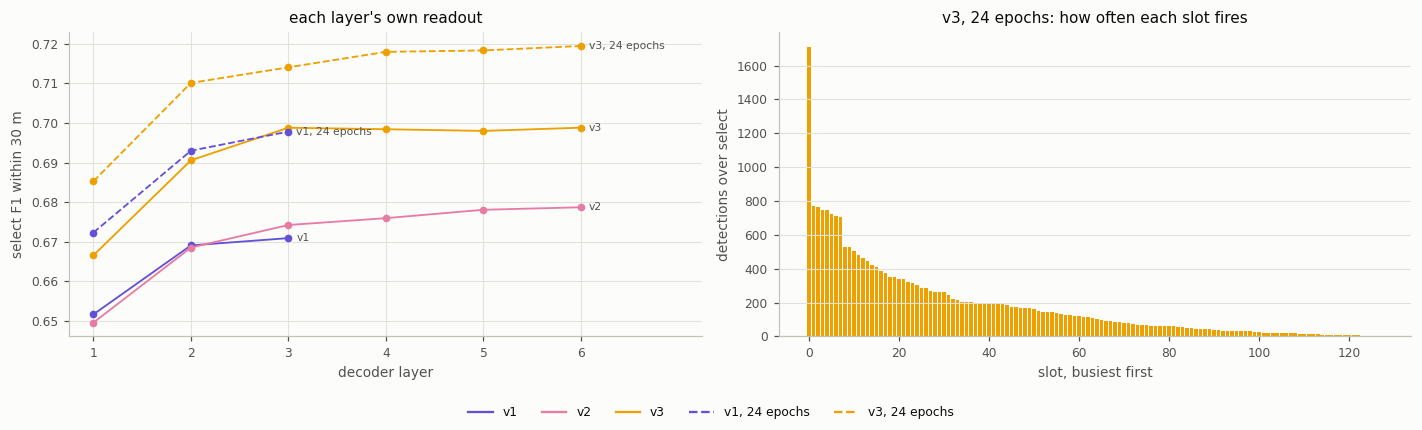

,v1,"v1, 24 epochs",v2,v3,"v3, 24 epochs","v3, 24 epochs, seed 1","v3, 24 epochs, seed 2","v3, 24 epochs, no camera"
detections a sample,5.259,5.265,4.445,4.804,5.238,5.153,5.189,8.092
targets a sample,7.264,7.264,7.264,7.264,7.264,7.264,7.264,7.264
duplicate pairs a sample,2.663,2.261,1.915,1.792,1.958,1.908,1.995,0.098
both hit distinct targets (neighbours),0.883,0.814,0.746,0.749,0.759,0.733,0.772,0.0
one hits nothing (true duplicates),1.78,1.447,1.169,1.043,1.199,1.175,1.222,0.098
share of detections in a duplicate pair,0.378,0.353,0.341,0.326,0.329,0.336,0.346,0.024
slots that ever fire,64 of 64,64 of 64,124 of 128,120 of 128,128 of 128,125 of 128,126 of 128,21 of 128
share of detections from the busiest eighth of the slots,0.311,0.299,0.481,0.471,0.457,0.411,0.454,0.971


In [26]:
def duplicate_split(name):
    """`evaluate.slot_numbers`' pairs (two detections of one class within 2 m), split: both hit distinct
    targets (two real agents side by side, such as pedestrians walking together), or at least one hits
    nothing (a true duplicate, or a false alarm beside a real agent)."""
    neighbours = with_false = 0
    for gt, pred in zip(gts, preds[name]):
        m = gt["mask"]
        det, tp, _ = evaluate.match(pred["conf"], pred["cls"], pred["xyz"][:, :2], gt["box"][m, :2], gt["cls"][m])
        xy, cls = pred["xyz"][det, :2], pred["cls"][det]
        close = (np.linalg.norm(xy[:, None] - xy[None], axis=-1) <= evaluate.HIT_M) & (cls[:, None] == cls[None])
        for a_, b_ in zip(*np.nonzero(np.triu(close, k=1))):
            if tp[a_] and tp[b_]:
                neighbours += 1
            else:
                with_false += 1
    return neighbours / len(gts), with_false / len(gts)


slot_rows = {}
for name in runs:
    r = reads[name]
    neighbours, with_false = duplicate_split(name)
    slot_rows[name] = {"detections a sample": r["detections_per_sample"], "targets a sample": targets_per_sample,
                       "duplicate pairs a sample": r["duplicate_pairs_per_sample"],
                       "  both hit distinct targets (neighbours)": neighbours,
                       "  one hits nothing (true duplicates)": with_false,
                       "share of detections in a duplicate pair": r["duplicate_share"],
                       "slots that ever fire": f"{r['slots_firing']} of {r['slots']}",
                       "share of detections from the busiest eighth of the slots": r["busiest_eighth_share"]}
display_slots = pd.DataFrame(slot_rows)
layer_f1 = {}
for name in compare:
    layer_f1[name] = []
    for layer_raw in raws[name]:
        rr = evaluate.readout(decode_all(layer_raw), gts, runs[name]["meta"]["prior_gap_m"])
        layer_f1[name].append((f1_of(rr), rr["recall_2m_within_30m"], rr["precision_2m_within_30m"], rr["centre_error_m"]))
fig, axes = plt.subplots(1, 2, figsize=(13, 3.9))
ends = []
for name, vals in layer_f1.items():
    x = np.arange(1, len(vals) + 1)
    axes[0].plot(x, [v[0] for v in vals], marker="o", ms=4, lw=1.2, **style(name))
    ends.append((name, x[-1], vals[-1][0]))
axes[0].set_xticks(range(1, max(len(v) for v in layer_f1.values()) + 1))
axes[0].set_xlabel("decoder layer")
axes[0].set_ylabel("select F1 within 30 m")
axes[0].set_title("each layer's own readout")
label_ends(axes[0], ends)
per_slot = np.stack([p["conf"] >= evaluate.THR for p in preds[focus]]).sum(0)
axes[1].bar(np.arange(len(per_slot)), np.sort(per_slot)[::-1], width=0.8,
            color=VARIANT_COLOURS[runs[focus]["args"]["variant"]])
axes[1].set_xlabel("slot, busiest first")
axes[1].set_ylabel("detections over select")
axes[1].set_title(f"{focus}: how often each slot fires")
axes[1].grid(axis="x", visible=False)
fig.legend(handles=legend_for(compare), loc="lower center", ncol=len(compare))
plt.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()
display_slots

In [27]:
pd.DataFrame({name: {f"layer {k + 1}": f"F1 {v[0]:.3f} · recall {v[1]:.3f} · precision {v[2]:.3f} · centre {v[3]:.2f} m"
                     for k, v in enumerate(vals)} for name, vals in layer_f1.items()})

,v1,v2,v3,"v1, 24 epochs","v3, 24 epochs"
layer 1,F1 0.652 · recall 0.626 · precision 0.679 · ce...,F1 0.650 · recall 0.583 · precision 0.732 · ce...,F1 0.667 · recall 0.609 · precision 0.736 · ce...,F1 0.672 · recall 0.641 · precision 0.707 · ce...,F1 0.685 · recall 0.626 · precision 0.757 · ce...
layer 2,F1 0.669 · recall 0.636 · precision 0.706 · ce...,F1 0.668 · recall 0.599 · precision 0.756 · ce...,F1 0.691 · recall 0.630 · precision 0.764 · ce...,F1 0.693 · recall 0.655 · precision 0.736 · ce...,F1 0.710 · recall 0.662 · precision 0.766 · ce...
layer 3,F1 0.671 · recall 0.638 · precision 0.708 · ce...,F1 0.674 · recall 0.609 · precision 0.755 · ce...,F1 0.699 · recall 0.643 · precision 0.766 · ce...,F1 0.698 · recall 0.658 · precision 0.742 · ce...,F1 0.714 · recall 0.665 · precision 0.771 · ce...
layer 4,NaN,F1 0.676 · recall 0.612 · precision 0.755 · ce...,F1 0.698 · recall 0.646 · precision 0.760 · ce...,NaN,F1 0.718 · recall 0.678 · precision 0.763 · ce...
layer 5,NaN,F1 0.678 · recall 0.617 · precision 0.753 · ce...,F1 0.698 · recall 0.645 · precision 0.760 · ce...,NaN,F1 0.718 · recall 0.677 · precision 0.765 · ce...
layer 6,NaN,F1 0.679 · recall 0.620 · precision 0.749 · ce...,F1 0.699 · recall 0.646 · precision 0.761 · ce...,NaN,F1 0.719 · recall 0.680 · precision 0.763 · ce...


**Reading it:**
- **No slot collapse:** every run uses nearly all its slots (v3 on 24 epochs: 128 of 128), and the busiest
  eighth makes 30% (64 slots) to 41–48% (128 slots) of the detections.
- **Duplicates are real but modest:** of the 1.8–2.7 close same-class pairs a sample, a third to two fifths
  are two real agents side by side. True duplicates run from 1.0 (v3) to 1.8 (v1) a sample; 1.2 for v3 on
  24 epochs.
- **Under-detection is the stronger sign:** 5.2 detections a sample against 7.3 targets. The plan's remedies
  (§5.2) are one-to-many matching or denoising queries for duplicates, and the class term's weight for
  under-detection; sections 5 and 7 show the missed agents are mostly far or hidden.
- **Refinement happens in the first three layers.** v3 on 12 epochs reads the same F1 at layer 3 as at
  layer 6 (0.699); on 24 epochs, layer 4 adds 0.004 and layers 5–6 another 0.001. What v3 gains over v2,
  which has the same six layers and 128 queries, comes from width (d 384, 12 heads, FFN 1536): +0.020.

## 11. What matters: causal, visible, nearest, pedestrian groups, traffic side

The owner's choices (plan §11.7–11.8): causal under the chosen rule (a 4 s look-ahead, a 2 m margin) and the
strict one; pedestrians grouped within 1.0 m, no group wider than 3 m. Recall here is over all ranges, as in
notebook 04 §4e; Q10 and Q11, read at step 6 on the report logs, are within 30 m.

In [28]:
matters = {}
for name in runs:
    r = reads[name]
    matters[name] = {key: r[f"recall_{key}"] for key in ("causal_chosen", "causal_strict", "visible", "hidden",
                                                          "nearest_1", "nearest_3", "nearest_5")}
    matters[name]["all targets"] = float(targets_df[name].hit.mean())
counts_ = {key: reads[next(iter(runs))][f"targets_{key}"] for key in ("causal_chosen", "causal_strict", "visible",
                                                                     "hidden", "nearest_1", "nearest_3", "nearest_5")}
counts_["all targets"] = len(targets_df[next(iter(runs))])
t_matters = pd.DataFrame(matters)
t_matters.insert(0, "targets", pd.Series(counts_))
t_matters

,targets,v1,"v1, 24 epochs",v2,v3,"v3, 24 epochs","v3, 24 epochs, seed 1","v3, 24 epochs, seed 2","v3, 24 epochs, no camera"
causal_chosen,2117,0.875,0.885,0.873,0.877,0.898,0.903,0.897,0.108
causal_strict,1139,0.875,0.882,0.874,0.878,0.892,0.888,0.889,0.135
visible,13544,0.554,0.592,0.561,0.591,0.626,0.627,0.622,0.052
hidden,18831,0.345,0.360,0.299,0.331,0.363,0.357,0.357,0.022
nearest_1,3747,0.734,0.756,0.738,0.763,0.792,0.785,0.784,0.082
nearest_3,9993,0.605,0.638,0.611,0.631,0.672,0.668,0.664,0.059
nearest_5,14900,0.534,0.572,0.539,0.565,0.608,0.605,0.600,0.053
all targets,32375,0.432,0.457,0.409,0.440,0.473,0.470,0.468,0.035


In [29]:
def group_numbers(name):
    found_, total, ped_det, ped_true, ped_hit, ped_n = 0, 0, 0, 0, 0, 0
    for i, (gt, pred) in enumerate(zip(gts, preds[name])):
        m = gt["mask"]
        _, _, hit = evaluate.match(pred["conf"], pred["cls"], pred["xyz"][:, :2], gt["box"][m, :2], gt["cls"][m])
        g = im.groups(gt["box"][m, :2], gt["cls"][m], radius=im.GROUP_M, max_width=im.GROUP_MAX_WIDTH_M)
        shown_ = (pred["conf"] >= evaluate.THR) & (pred["cls"] == im.PEDESTRIAN)
        members = gt["box"][m][g >= 0, :2]
        near = np.hypot(*(pred["xyz"][shown_][:, None, :2] - members[None]).transpose(2, 0, 1)) <= evaluate.HIT_M if len(members) else np.zeros((int(shown_.sum()), 0), bool)
        ped_det += int(shown_.sum())
        ped_true += int(near.any(1).sum()) if near.size else 0
        ped_n += int((g >= 0).sum())
        ped_hit += int(((g >= 0) & (hit >= 0)).sum())
        for gid in np.unique(g[g >= 0]):
            total += 1
            found_ += bool(near[:, g[g >= 0] == gid].any()) if near.size else False
    return {"pedestrian recall, each one": ped_hit / max(ped_n, 1), "pedestrian groups found": found_ / max(total, 1),
            "groups": total, "pedestrians": ped_n,
            "pedestrian detections near some pedestrian (group-aware precision)": ped_true / max(ped_det, 1)}


pd.DataFrame({name: group_numbers(name) for name in runs})

,v1,"v1, 24 epochs",v2,v3,"v3, 24 epochs","v3, 24 epochs, seed 1","v3, 24 epochs, seed 2","v3, 24 epochs, no camera"
"pedestrian recall, each one",0.357,0.355,0.315,0.334,0.355,0.349,0.358,0.0
pedestrian groups found,0.454,0.457,0.413,0.439,0.470,0.466,0.479,0.0
groups,9933.000,9933.000,9933.000,9933.000,9933.000,9933.000,9933.000,9933.0
pedestrians,14251.000,14251.000,14251.000,14251.000,14251.000,14251.000,14251.000,14251.0
pedestrian detections near some pedestrian (group-aware precision),0.653,0.670,0.706,0.697,0.663,0.659,0.655,0.0


**By traffic side** (plan §11.10: measured first). Select has only two Singapore logs, so the left-hand
numbers here are wide; step 6's report logs have eight.

In [30]:
def city(log_name):
    with open(NAVSIM / "navsim_logs" / "trainval" / f"{log_name}.pkl", "rb") as fh:
        return pickle.load(fh)[0]["map_location"]


cities = {log_name: city(log_name) for log_name in splits["select"]}
side_of_log = {log_name: "left-hand (Singapore)" if c.startswith("sg") else "right-hand (US)" for log_name, c in cities.items()}
sides = {}
for name in runs:
    c = counts[name].copy()
    c["side"] = [side_of_log[n] for n in c.index]
    g = c.groupby("side").sum()
    for s, row in g.iterrows():
        sides.setdefault((s, "logs"), {})[name] = int((c.side == s).sum())
        sides.setdefault((s, "recall within 30 m"), {})[name] = row.hits / row.targets
        sides.setdefault((s, "precision within 30 m"), {})[name] = row.true / row.detections
pd.DataFrame(sides).T

v1  v1, 24 epochs      v2  \
left-hand (Singapore) logs                    2.000          2.000   2.000   
                      recall within 30 m      0.330          0.368   0.340   
                      precision within 30 m   0.673          0.755   0.750   
right-hand (US)       logs                   49.000         49.000  49.000   
                      recall within 30 m      0.640          0.661   0.622   
                      precision within 30 m   0.708          0.742   0.749   

                                                 v3  v3, 24 epochs  \
left-hand (Singapore) logs                    2.000          2.000   
                      recall within 30 m      0.358          0.406   
                      precision within 30 m   0.672          0.729   
right-hand (US)       logs                   49.000         49.000   
                      recall within 30 m      0.648          0.682   
                      precision within 30 m   0.762          0.764   

                                             v3, 24 epochs, seed 1  \
left-hand (Singapore) logs                                   2.000   
                      recall within 30 m                     0.396   
                      precision within 30 m                  0.724   
right-hand (US)       logs                                  49.000   
                      recall within 30 m                     0.675   
                      precision within 30 m                  0.770   

                                             v3, 24 epochs, seed 2  \
left-hand (Singapore) logs                                   2.000   
                      recall within 30 m                     0.425   
                      precision within 30 m                  0.721   
right-hand (US)       logs                                  49.000   
                      recall within 30 m                     0.667   
                      precision within 30 m                  0.768   

                                             v3, 24 epochs, no camera  
left-hand (Singapore) logs                                      2.000  
                      recall within 30 m                        0.066  
                      precision within 30 m                     0.003  
right-hand (US)       logs                                     49.000  
                      recall within 30 m                        0.057  
                      precision within 30 m                     0.035

**Reading it:**
- **The agents that matter are found far more often than the rest:** causal recall (chosen rule, 2,117
  targets) is 0.90 for v3 on 24 epochs, against 0.47 for all targets and 0.11 without the camera. The
  nearest target is found 79% of the time; the nearest five, 61%.
- **Line of sight decides much of it:** 0.63 for visible targets, 0.36 for hidden ones.
- **Counting a pedestrian group as found when any member is** raises pedestrian recall from 0.36 to 0.47
  (groups at 1.0 m, at most 3 m wide). Pedestrian detections near some pedestrian: 0.66.
- **Left-hand traffic reads lower, on two logs:** Singapore recall is 0.40–0.43 against 0.67–0.68 in the US
  cities for the three seeds, with precision 0.72–0.73 against 0.76–0.77. Two logs cannot separate the
  traffic side from the city's look; step 6's eight Singapore report logs can say more (§11.10).

## 12. Does it use the camera geometry now?

Notebook 02b §1's test, on the trained models (plan §4.1: "step 5: run the same test on the trained
models"). The geometry input alone is changed, the tokens are not: the camera turned by 2° (yaw), tilted by
2° (pitch), or the rays removed from the keys. A side-car that places agents by their rays turns its
detections with the camera; one that has learnt where each token sits ignores the change.

In [31]:
def rotate(P, yaw_deg=0.0, pitch_deg=0.0):
    """Projections composed with a rotation of the ego frame: what the camera would be if turned."""
    a_, b_ = math.radians(yaw_deg), math.radians(pitch_deg)
    rz = np.array([[math.cos(a_), -math.sin(a_), 0, 0], [math.sin(a_), math.cos(a_), 0, 0], [0, 0, 1, 0], [0, 0, 0, 1]])
    ry = np.array([[math.cos(b_), 0, math.sin(b_), 0], [0, 1, 0, 0], [-math.sin(b_), 0, math.cos(b_), 0], [0, 0, 0, 1]])
    return (P.astype(np.float64) @ (rz @ ry)).astype(np.float32)


cases = {"yaw +2°": (rotate(P_SEL, yaw_deg=2.0), 1.0), "yaw −2°": (rotate(P_SEL, yaw_deg=-2.0), 1.0),
         "pitch +2°": (rotate(P_SEL, pitch_deg=2.0), 1.0), "no rays in the keys": (P_SEL, 0.0)}


def turn(base, other):
    """Mean change of detection azimuth (°) and median range ratio, over slots detected in both."""
    cb, _ = conf_cls(base)
    co, _ = conf_cls(other)
    both = (cb >= evaluate.THR) & (co >= evaluate.THR)
    a_b = np.degrees(np.arctan2(base["box"][..., 1], base["box"][..., 0]))[both]
    a_o = np.degrees(np.arctan2(other["box"][..., 1], other["box"][..., 0]))[both]
    r_b = np.hypot(base["box"][..., 0], base["box"][..., 1])[both]
    r_o = np.hypot(other["box"][..., 0], other["box"][..., 1])[both]
    return float(np.mean(a_o - a_b)), float(np.median(r_o / np.maximum(r_b, 1e-3)))


geometry = {}
for name in compare:
    model = load_model(name)
    base = raws[name][-1]
    geometry[(name, "as recorded")] = {"recall within 30 m": reads[name]["recall_2m_within_30m"],
                                       "precision within 30 m": reads[name]["precision_2m_within_30m"],
                                       "detections turn by (°)": 0.0, "their range ×": 1.0}
    for case, (P, scale) in cases.items():
        raw = outputs(model, projections=P, ray_scale=scale)[-1]
        rr = evaluate.readout(decode_all(raw), gts, runs[name]["meta"]["prior_gap_m"])
        shift, ratio = turn(base, raw)
        geometry[(name, case)] = {"recall within 30 m": rr["recall_2m_within_30m"],
                                  "precision within 30 m": rr["precision_2m_within_30m"],
                                  "detections turn by (°)": shift, "their range ×": ratio}
pd.DataFrame(geometry).T

recall within 30 m  precision within 30 m  \
v1            as recorded                       0.638                  0.708   
              yaw +2°                           0.638                  0.707   
              yaw −2°                           0.635                  0.705   
              pitch +2°                         0.586                  0.701   
              no rays in the keys               0.543                  0.704   
v2            as recorded                       0.620                  0.749   
              yaw +2°                           0.620                  0.749   
              yaw −2°                           0.618                  0.750   
              pitch +2°                         0.549                  0.724   
              no rays in the keys               0.502                  0.758   
v3            as recorded                       0.646                  0.761   
              yaw +2°                           0.647                  0.758   
              yaw −2°                           0.644                  0.763   
              pitch +2°                         0.607                  0.749   
              no rays in the keys               0.573                  0.750   
v1, 24 epochs as recorded                       0.658                  0.742   
              yaw +2°                           0.659                  0.742   
              yaw −2°                           0.656                  0.740   
              pitch +2°                         0.592                  0.719   
              no rays in the keys               0.543                  0.728   
v3, 24 epochs as recorded                       0.680                  0.763   
              yaw +2°                           0.679                  0.760   
              yaw −2°                           0.676                  0.764   
              pitch +2°                         0.627                  0.743   
              no rays in the keys               0.580                  0.743   

                                   detections turn by (°)  their range ×  
v1            as recorded                           0.000          1.000  
              yaw +2°                              -0.015          1.000  
              yaw −2°                               0.016          1.000  
              pitch +2°                            -0.108          1.013  
              no rays in the keys                  -0.196          1.015  
v2            as recorded                           0.000          1.000  
              yaw +2°                              -0.058          1.000  
              yaw −2°                               0.058          1.000  
              pitch +2°                             0.010          1.016  
              no rays in the keys                  -0.187          1.013  
v3            as recorded                           0.000          1.000  
              yaw +2°                              -0.054          1.000  
              yaw −2°                               0.056          1.000  
              pitch +2°                            -0.037          1.011  
              no rays in the keys                  -0.066          1.012  
v1, 24 epochs as recorded                           0.000          1.000  
              yaw +2°                              -0.049          1.000  
              yaw −2°                               0.055          1.000  
              pitch +2°                            -0.160          1.016  
              no rays in the keys                  -0.231          1.019  
v3, 24 epochs as recorded                           0.000          1.000  
              yaw +2°                              -0.086          1.000  
              yaw −2°                               0.086          1.000  
              pitch +2°                            -0.050          1.014  
              no rays in the keys                  -0.160          1.015

**Reading it:**
- **Turning the camera by 2° turns the trained side-car's detections by 0.02–0.09°,** under a twentieth of
  the turn, and costs no recall: it still places agents by what the tokens show, not by their rays (one
  epoch in, 0.01°).
- **Yet the rays matter more than at epoch 1:** removing them costs 0.07–0.12 recall (v3 on 24 epochs: from
  0.680 to 0.580), against 0.047 at epoch 1. Tilting the camera by 2° costs 0.04–0.07 and moves the
  detections 1–2% farther. The rays act as a learnt code for where each token sits, not as geometry.
- **For nuScenes (step 7):** a camera turned or tilted against NAVSIM's will not be corrected by the rays.
  Warping its images to NAVSIM's camera first (plan §4.1, §11.12) is what can align them.

## 13. Where it looked: cross-attention

For explainability, each detection carries its last-layer cross-attention: where in the image it gathered
its evidence (plan §4.4). One epoch in (notebook 02b §2), detected slots attended to the same band along
the horizon. **Measured here on the trained models:** for each detection on 300 random select samples, the
share of its attention (mean over heads) that falls on the tokens its own box covers on the image, against
the share of the image those tokens are. A ratio of 1 is attention spread evenly; a slot that looks at its
own agent scores well above 1.

In [32]:
def attention(mha, q_in, k_in):
    """(B, heads, Nq, Nk) attention weights of `mha` (sidecar.MHA) for these inputs."""
    b, nq, d = q_in.shape
    dh = d // mha.h
    q_ = mha.q(q_in).view(b, nq, mha.h, dh).transpose(1, 2)
    k_ = mha.k(k_in).view(b, -1, mha.h, dh).transpose(1, 2)
    return torch.softmax(q_ @ k_.transpose(-1, -2) / math.sqrt(dh), dim=-1)


@torch.no_grad()
def last_cross_attention(model, tokens, projection):
    """sidecar.SideCar.forward written out (eval mode), keeping the last layer's cross-attention."""
    mem = model.ln_tok(model.proj(tokens))
    keys = mem + model.ray_pos(projection)
    a = model.query[None].expand(len(tokens), -1, -1)
    ref = model.ref[None].expand(len(tokens), -1, -1)
    for layer in model.layers:
        pos = model.pos_mlp(ref * model.scale)
        h = layer.ln_sa(a)
        a = a + layer.sa(h + pos, h + pos, h)
        q_in = layer.ln_ca(a) + pos
        cross = attention(layer.ca, q_in, keys)
        a = a + layer.ca(q_in, keys, mem)
        a = a + layer.ffn(layer.ln_ff(a))
        ref = ref + layer.ref_mlp(a)
    return cross.mean(1), ref, layer.cls_head(a), layer.box_head(a)


def box_cells(P, box):
    """The 16x32 token cells a box's image rectangle covers (dilated by one cell), as a flat index."""
    uv, depth = views.project(P, views.box_corners(box[None])[0])
    front = depth > 0.5
    if not front.any():
        return np.zeros(0, int)
    lo = np.clip(uv[front].min(0), 0, [511, 255])
    hi = np.clip(uv[front].max(0), 0, [511, 255])
    c0, r0 = int(lo[0] // 16) - 1, int(lo[1] // 16) - 1
    c1, r1 = int(hi[0] // 16) + 1, int(hi[1] // 16) + 1
    cols, rows_ = np.arange(max(c0, 0), min(c1, 31) + 1), np.arange(max(r0, 0), min(r1, 15) + 1)
    return (rows_[:, None] * 32 + cols[None]).ravel()


lift = {}
picked = np.random.default_rng(7).choice(len(select), 300, replace=False)
for name in compare:
    model = load_model(name).float()
    values = []
    for start in range(0, len(picked), 50):
        idx = picked[start : start + 50]
        tok = torch.from_numpy(TOK[idx].astype(np.float32)).to(device)
        P = torch.from_numpy(P_SEL[idx]).to(device)
        cross, centre, logits, box_rest = last_cross_attention(model, tok, P)
        conf = 1 - torch.softmax(logits, -1)[..., tg.NONE]
        cross, centre, conf, box_rest = (x.float().cpu().numpy() for x in (cross, centre, conf, box_rest))
        for b_, i in enumerate(idx):
            for q_ in np.flatnonzero(conf[b_] >= evaluate.THR):
                box = np.r_[centre[b_, q_], np.exp(box_rest[b_, q_, :3]), math.atan2(box_rest[b_, q_, 3], box_rest[b_, q_, 4])]
                cells = box_cells(P_SEL[i], box)
                if len(cells):
                    values.append(cross[b_, q_, cells].sum() / (len(cells) / 512))
    lift[name] = np.array(values)
pd.DataFrame({name: {"detections": len(v), "median ratio": np.median(v), "share above 2": float((v > 2).mean()),
                     "share below 1": float((v < 1).mean())} for name, v in lift.items()})

,v1,v2,v3,"v1, 24 epochs","v3, 24 epochs"
detections,1559.000,1291.000,1458.000,1523.000,1546.000
median ratio,3.353,1.890,2.489,3.705,3.002
share above 2,0.856,0.439,0.651,0.892,0.734
share below 1,0.004,0.031,0.052,0.012,0.039


**Four detections of the focus variant**, each with its attention drawn over the image the ViT read:

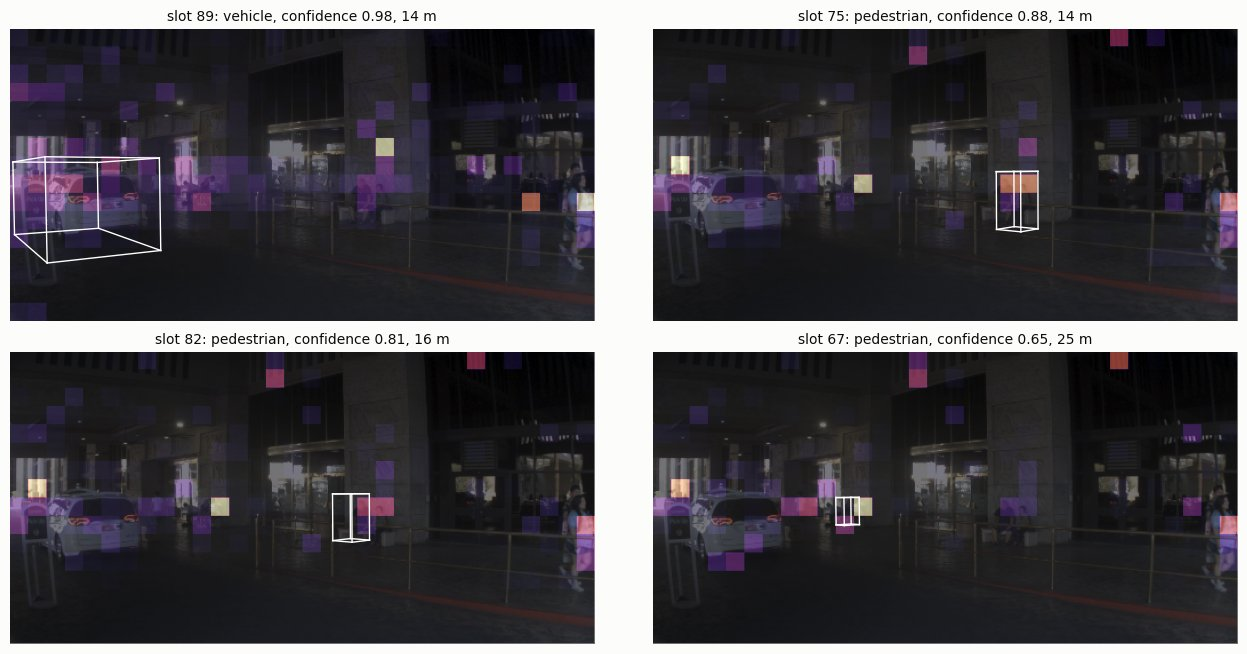

In [33]:
model = load_model(focus).float()
i = shown[0]
tok = torch.from_numpy(TOK[[i]].astype(np.float32)).to(device)
cross, centre, logits, box_rest = last_cross_attention(model, tok, torch.from_numpy(P_SEL[[i]]).to(device))
conf = (1 - torch.softmax(logits, -1)[0, :, tg.NONE]).cpu().numpy()
cross, centre, box_rest = cross[0].cpu().numpy(), centre[0].cpu().numpy(), box_rest[0].cpu().numpy()
cls_ = torch.softmax(logits[0], -1)[:, : tg.NONE].argmax(-1).cpu().numpy()
image = image_of(i)
fig, axes = plt.subplots(2, 2, figsize=(13, 6.6))
for ax, q_ in zip(axes.ravel(), np.argsort(-conf)[:4]):
    ax.imshow(image)
    heat = cross[q_].reshape(16, 32)
    ax.imshow(np.kron(heat / heat.max(), np.ones((16, 16))), cmap="magma", alpha=0.55, extent=(0, 512, 256, 0))
    box = np.r_[centre[q_], np.exp(box_rest[q_, :3]), math.atan2(box_rest[q_, 3], box_rest[q_, 4])]
    for (u0, v0), (u1, v1) in views.box_edges_2d(P_SEL[i], box[None])[0]:
        ax.plot([u0, u1], [v0, v1], color="white", lw=1.0)
    ax.set_title(f"slot {q_}: {views.CLASS_NAMES[cls_[q_]]}, confidence {conf[q_]:.2f}, {np.hypot(*centre[q_, :2]):.0f} m")
    ax.set_xlim(0, 512)
    ax.set_ylim(256, 0)
    ax.axis("off")
plt.tight_layout()
views.show_jpeg(fig)

**Reading it:**
- **Each detection looks mostly at its own agent:** at the median, the attention on the tokens its box
  covers is 3.0 times their share of the image for v3 on 24 epochs, and 73% of detections exceed twice.
  One epoch in, detected slots looked at the same band along the horizon (notebook 02b §2).
- **The three-layer v1 concentrates most** (3.4, and 3.7 on 24 epochs); the six-layer v2 least (1.9).
- **In the pictures,** each slot's brightest tokens sit on or beside its agent, with weaker attention on
  other agents. For explanations (plan §4.4), a detection's attention points at the right place most of the
  time, but not only there.

## 14. Summary for the review

**What step 5 chose, by the rules committed before it ran:** v3 (18.44 M) for 24 epochs. On select it
reads F1 0.717 within 30 m (seeds 0.713–0.720), recall 0.666–0.680 and precision 0.763–0.770, with causal
recall 0.90. Every gate held.

**What it does well** (*measured*, select):
- it places agents in the right direction, to under a degree;
- it finds the agents that matter: 90% of causal targets, 79% of the nearest ones, 96% of moving vehicles
  within 20 m;
- it does not confuse classes, collapse its slots, or give parked cars the ego's motion;
- its 1 s paths beat constant velocity by about 5%.

**Where it fails:**
1. **Distance:** from about 25 m the median depth error passes 1 m, and nearly a third of the agents beyond
   30 m are placed more than 2 m off. This is the largest share of the misses (43%) and of the false alarms
   (45%).
2. **Hidden agents:** recall 0.36, against 0.63 for visible ones.
3. **Cyclists:** 212 on select, found as cyclists 4% of the time.
4. **Under-detection:** 5.2 detections a sample against 7.3 targets, with about one true duplicate a sample.

**For the owner's review:**
- **Step 6:** the report logs read once, for v3 on 24 epochs at three seeds and the no-camera control.
- **The no-camera control** trained unhealthily: keep it as the baseline (it finds almost nothing, as the
  first pass's did), or retrain it in fp32 first.
- **Open from the second review:** weighting what matters (step 5c, §11.9) and head changes (§11.11).
  Section 7 suggests the head to try first: depth along the ray, with an uncertainty.
- **v3's layers 4–6 add little:** a three-layer v3 (about 10 M, *estimate*) would likely do as well for
  less. Not run, and not a choice step 5 makes.